<a href="https://www.mbd.rwth-aachen.de/">
    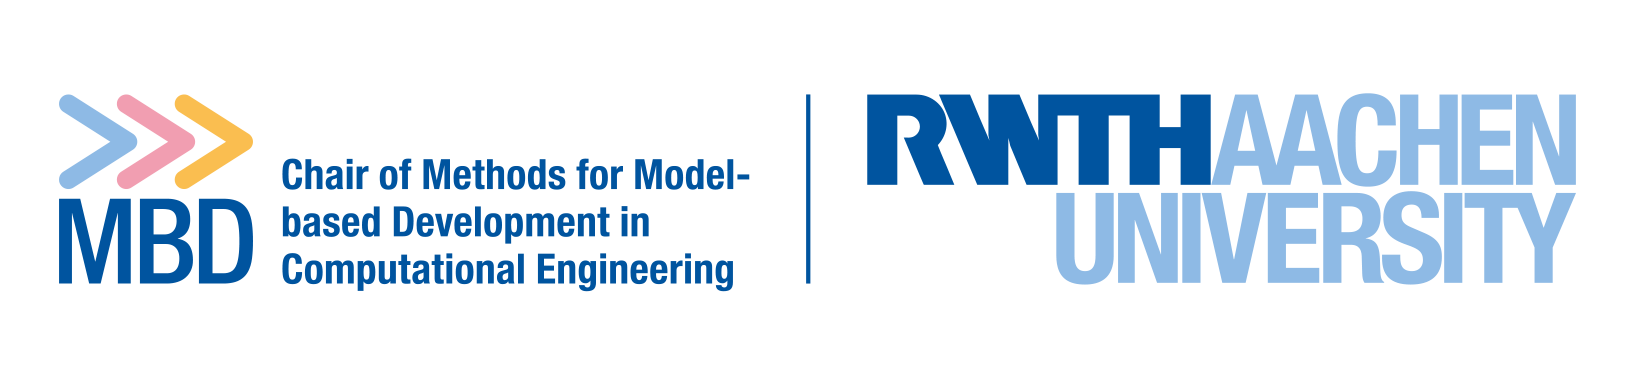
</a>
<a href="https://www.cpbl.rwth-aachen.de/">
    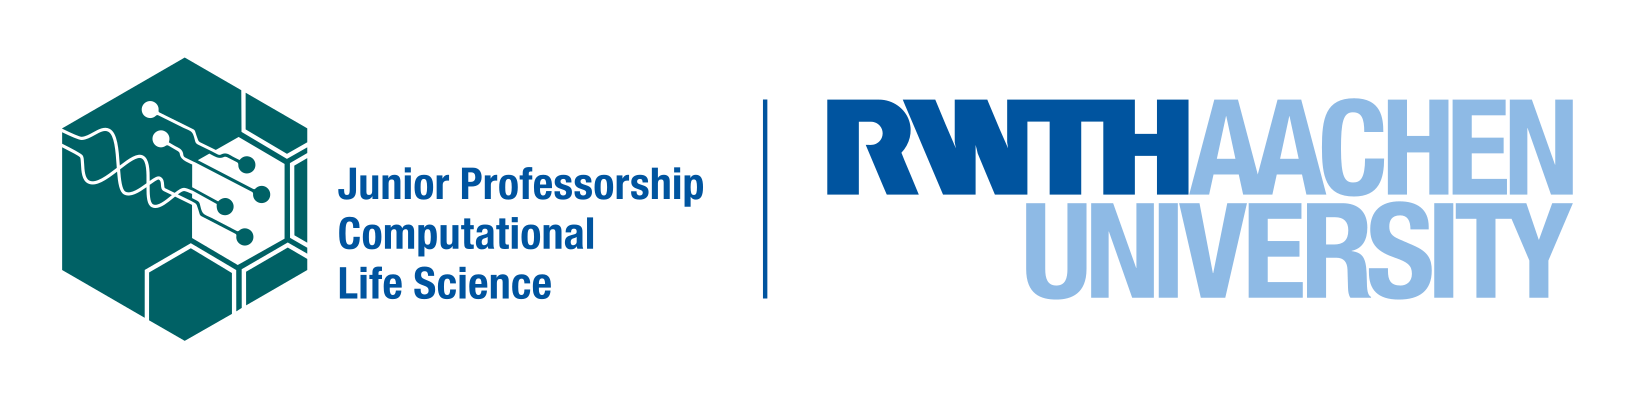
</a>

# Societal Challenges Datathon

Name: **Bhoomi**

Student number (Matrikelnummer): **485556**

**Combining all the columns in a dataframe**

In [ ]:
import os
import pandas as pd
import numpy as np

base_path = "data/raw/"
combined_df = None

for file in os.listdir(base_path):
    if not file.lower().endswith(".xpt"):
        continue

    file_path = os.path.join(base_path, file)
    print(f"Processing {file_path}...")

    df = pd.read_sas(file_path, format="xport")

    if "SEQN" not in df.columns:
        print(f"SEQN not found in {file}, skipping")
        continue

    for col in df.select_dtypes(include="object"):
        df[col] = df[col].str.decode("utf-8", errors="ignore")

    df = df.rename(
        columns={c: f"{c}"
                 for c in df.columns if c != "SEQN"}
    )

    if combined_df is None:
        combined_df = df
    else:
        combined_df = combined_df.merge(df, on="SEQN", how="outer")

output_path = "NHANES_all_columns_combined.csv"
combined_df.to_csv(output_path, index=False)

print(f"Saved combined CSV to {output_path}")


In [ ]:
combined_df.shape

: 

**Columns used** : I have used the columns mentioned in the final_columns.txt file for my model

In [204]:
with open("finalcodes.txt") as f:
    selected_cols = [c.strip() for c in f if c.strip()]

df_subset = combined_df.loc[:, combined_df.columns.intersection(selected_cols)]

df_subset.to_csv("NHANES_subset_step1.csv", index=False)

print(df_subset.shape)

(11933, 47)


**Renaming Columns**

In [ ]:
print("Original columns:")
print(df_subset.columns.tolist())

column_mapping = {
    # ---- Alcohol ----
    "ALQ121": "alcohol_use_frequency_last_12m",

    # ---- Blood Pressure & Cholesterol ----
    "BPQ020": "bp_high_ever",
    "BPQ080": "cholesterol_high_ever",

    # ---- Early Life / Childhood ----
    "ECD070A": "birth_weight_pounds",
    "ECD070B": "birth_weight_ounces",
    "ECQ080": "childhood_overweight",

    # ---- Health Insurance ----
    "HIQ011": "insurance_covered",
    "HIQ032A": "insurance_private",
    "HIQ032B": "insurance_medicare",
    "HIQ032D": "insurance_medicaid",
    "HIQ210": "care_delayed_due_to_cost",

    # ---- Healthcare Access ----
    "HUQ010": "self_rated_health",
    "HUQ030": "usual_place_for_care",

    # ---- Income / SES ----
    "IND310": "total_savings",
    "INDFMMPI": "poverty_income_ratio",

    # ---- Kidney / Urology ----
    "KIQ481": "nighttime_urination_frequency",

    # ---- Mental Health (Depression) ----
    "DPQ010": "depression_interest_loss",
    "DPQ020": "depression_low_mood",
    "DPQ030": "depression_sleep_issues",
    "DPQ040": "depression_fatigue",
    "DPQ050": "depression_appetite_change",
    "DPQ060": "depression_self_worth",
    "DPQ070": "depression_concentration",

    # ---- Oral Health ----
    "OHQ620": "gum_disease",
    "OHQ660": "mouth_pain",
    "OHQ670": "difficulty_chewing",
    "OHQ845": "oral_health_self_rating",

    # ---- Physical Activity ----
    "PAD680": "sitting_time_per_day",
    "PAD790Q": "frequency_moderate_activity",
    "PAD800": "duration_moderate_activity",
    "PAD810Q": "frequency_vigorous_activity",
    "PAD820": "duration_vigorous_activity",
    "PAQ706": "days_physicallyactive_last7days",
    "PAQ711": "screen_time_per_day",

    # ---- Smoking ----
    "SMQ020": "smoking_ever",
    "SMD460": "cigarettes_per_day",
    "SMDANY": "used_tobacco_last_5days",
    "SMD630": "First_smoke_age",
    "SMD641": "cigarrete_smokedays_last_30days",
    "SMD650": "cigarette_per_day",

    # ---- Body Measures ----
    "WHD010": "height_cm",
    "WHD020": "weight_kg",
    "WHD050": "weight_change_last_year",
    "WHQ070": "attempted_weight_loss",
    
    # ---- target variable ----
    "DIQ010": "diabetes"
}

df_subset = df_subset.rename(columns=column_mapping)

print("\nRenamed columns:")
print(df_subset.columns.tolist())

unmapped = [c for c in df.columns if c.isupper() and len(c) <= 6]
if unmapped:
    print("\nUnmapped coded columns detected:")
    print(unmapped)
else:
    print("\nAll coded columns mapped successfully")


df_subset.to_csv("NHANES_subset_step2.csv", index=False)

print("\nDataset saved as NHANES_subset_step2.csv")

Original columns:
['SEQN', 'ALQ121', 'BPQ020', 'BPQ080', 'DIQ010', 'ECD070A', 'ECD070B', 'ECQ080', 'HIQ011', 'HIQ032A', 'HIQ032B', 'HIQ032D', 'HIQ210', 'HUQ010', 'HUQ030', 'INDFMMPI', 'IND310', 'KIQ481', 'DPQ010', 'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'OHQ845', 'OHQ620', 'OHQ660', 'OHQ670', 'PAD790Q', 'PAD800', 'PAD810Q', 'PAD820', 'PAD680', 'PAQ706', 'PAQ711', 'SMQ020', 'SMD641', 'SMD650', 'SMD630', 'SMD460', 'SMD470', 'SMDANY', 'WHD010', 'WHD020', 'WHD050', 'WHQ070']

Renamed columns:
['SEQN', 'alcohol_use_frequency_last_12m', 'bp_high_ever', 'cholesterol_high_ever', 'diabetes', 'birth_weight_pounds', 'birth_weight_ounces', 'childhood_overweight', 'insurance_covered', 'insurance_private', 'insurance_medicare', 'insurance_medicaid', 'care_delayed_due_to_cost', 'self_rated_health', 'usual_place_for_care', 'poverty_income_ratio', 'total_savings', 'nighttime_urination_frequency', 'depression_interest_loss', 'depression_low_mood', 'depression_sleep_issues', 'depressi

**Replace missing codes**

In [206]:
missing_codes = [
    7, 9, 77, 99,
    777, 999,
    7777, 9999
]

df_subset = df_subset.replace(missing_codes, np.nan)

In [207]:
df_subset["diabetes"].value_counts(dropna=False)

diabetes
2.0    10371
1.0     1081
3.0      284
NaN      197
Name: count, dtype: int64

In [208]:
# Convert everything except target to numeric where possible
for col in df_subset.columns:
    if col != "diabetes":
        df_subset[col] = pd.to_numeric(df_subset[col], errors="coerce")

# Ensure diabetes is binary integer
df_subset["diabetes"] = df_subset["diabetes"].astype("Int64")

In [209]:
print("\nDiabetes value counts:")
print(df_subset["diabetes"].value_counts(dropna=False))


Diabetes value counts:
diabetes
2       10371
1        1081
3         284
<NA>      197
Name: count, dtype: Int64


**Merge Borerline with diabetes**

In [210]:
df_subset["diabetes"] = df_subset["diabetes"].replace({
    1: 1,  # diabetes
    3: 1,  # borderline / prediabetes
    2: 0   # no diabetes
})

df_subset = df_subset.dropna(subset=["diabetes"])

df_subset["diabetes"] = df_subset["diabetes"].astype(int)

print("\nFinal binary target distribution:")
print(df_subset["diabetes"].value_counts())

df_subset.to_csv("NHANES_subset_step2.csv", index=False)


Final binary target distribution:
diabetes
0    10371
1     1365
Name: count, dtype: int64


In [211]:
df_subset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11736 entries, 0 to 11932
Data columns (total 47 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   SEQN                             11736 non-null  float64
 1   alcohol_use_frequency_last_12m   4037 non-null   float64
 2   bp_high_ever                     8485 non-null   float64
 3   cholesterol_high_ever            8442 non-null   float64
 4   diabetes                         11736 non-null  int64  
 5   birth_weight_pounds              1883 non-null   float64
 6   birth_weight_ounces              2729 non-null   float64
 7   childhood_overweight             124 non-null    float64
 8   insurance_covered                11678 non-null  float64
 9   insurance_private                5747 non-null   float64
 10  insurance_medicare               2775 non-null   float64
 11  insurance_medicaid               2489 non-null   float64
 12  care_delayed_due_to_cos

In [212]:
df_subset.describe()

,SEQN,alcohol_use_frequency_last_12m,bp_high_ever,cholesterol_high_ever,diabetes,birth_weight_pounds,birth_weight_ounces,childhood_overweight,insurance_covered,insurance_private,...,cigarrete_smokedays_last_30days,cigarette_per_day,First_smoke_age,cigarettes_per_day,years_smoked,used_tobacco_last_5days,height_cm,weight_kg,weight_change_last_year,attempted_weight_loss
count,11736.000000,4.037000e+03,8485.000000,8442.000000,11736.000000,1883.000000,2.729000e+03,124.000000,11678.000000,5747.0,...,2.650000e+02,1126.000000,22.000000,1.043100e+04,2.564000e+03,6250.000000,8383.000000,8350.000000,8266.000000,8480.000000
mean,136349.693422,4.239039e+00,1.650206,1.633381,0.116309,6.414233,6.141810e+00,1.080645,1.073643,1.0,...,1.116604e+01,11.688277,13.363636,3.217333e-01,4.793292e-01,1.794880,66.359776,179.571737,181.581176,1.545401
std,3445.622078,3.250460e+00,0.476933,0.481910,0.320609,1.577758,4.885047e+00,0.273394,0.261200,0.0,...,8.815597e+00,10.163533,1.733300,6.082103e-01,6.927258e-01,0.403822,4.149165,48.084156,51.223333,0.497964
min,130378.000000,5.397605e-79,1.000000,1.000000,0.000000,3.000000,5.397605e-79,1.000000,1.000000,1.0,...,5.397605e-79,1.000000,10.000000,5.397605e-79,5.397605e-79,1.000000,40.000000,63.000000,67.000000,1.000000
25%,133363.500000,2.000000e+00,1.000000,1.000000,0.000000,6.000000,2.000000e+00,1.000000,1.000000,1.0,...,3.000000e+00,4.000000,12.000000,5.397605e-79,5.397605e-79,2.000000,63.000000,145.000000,145.000000,1.000000
50%,136356.500000,4.000000e+00,2.000000,2.000000,0.000000,6.000000,6.000000e+00,1.000000,1.000000,1.0,...,1.000000e+01,10.000000,13.000000,5.397605e-79,5.397605e-79,2.000000,66.000000,173.000000,175.000000,2.000000
75%,139328.250000,6.000000e+00,2.000000,2.000000,0.000000,8.000000,1.100000e+01,1.000000,1.000000,1.0,...,2.000000e+01,20.000000,14.000000,5.397605e-79,1.000000e+00,2.000000,69.000000,205.000000,210.000000,2.000000
max,142310.000000,1.000000e+01,2.000000,2.000000,1.000000,11.000000,1.500000e+01,2.000000,2.000000,1.0,...,3.000000e+01,95.000000,16.000000,2.000000e+00,2.000000e+00,2.000000,83.000000,530.000000,530.000000,2.000000


**Missing values**

In [213]:
missing = df_subset.isnull().mean().sort_values(ascending=False)
missing

First_smoke_age                    0.998125
childhood_overweight               0.989434
cigarrete_smokedays_last_30days    0.977420
cigarette_per_day                  0.904056
days_physicallyactive_last7days    0.844325
birth_weight_pounds                0.839554
insurance_medicaid                 0.787918
years_smoked                       0.781527
birth_weight_ounces                0.767468
insurance_medicare                 0.763548
screen_time_per_day                0.756817
duration_vigorous_activity         0.687117
alcohol_use_frequency_last_12m     0.656016
nighttime_urination_frequency      0.558538
total_savings                      0.539707
depression_interest_loss           0.531612
depression_concentration           0.531016
depression_self_worth              0.531016
depression_fatigue                 0.530930
depression_low_mood                0.530760
depression_sleep_issues            0.530675
depression_appetite_change         0.530590
insurance_private               

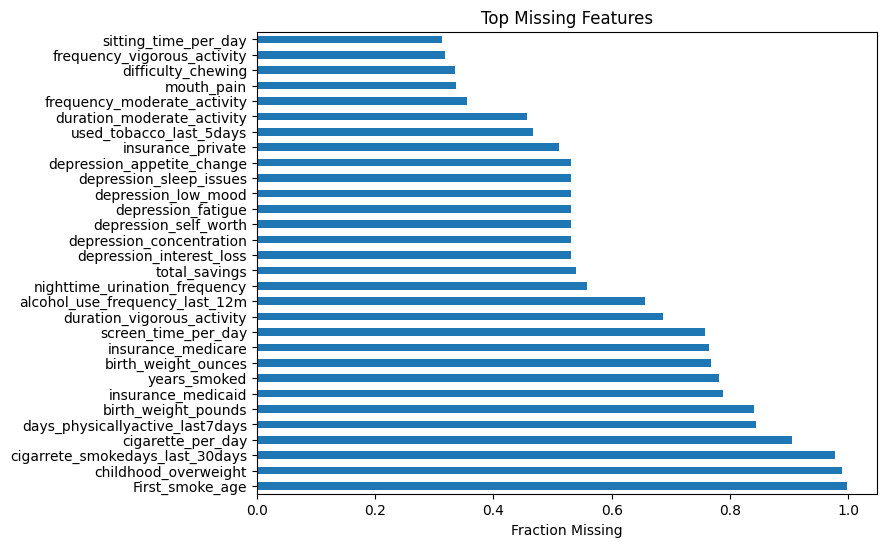

In [214]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
missing.head(30).plot(kind="barh")
plt.xlabel("Fraction Missing")
plt.title("Top Missing Features")
plt.show()

In [215]:
smoking_cols = [
    'cigarrete_smokedays_last_30days',
    'used_tobacco_last_5days',
    'cigarette_per_day'
]

alcohol_cols = [
    'alcohol_use_frequency_last_12m'
]

In [216]:
df_subset['is_smoker'] = df_subset['smoking_ever'].map({1: 1, 2: 0})

df_subset['is_smoker'] = df_subset['is_smoker'].fillna(0).astype(int)

for col in smoking_cols:
    df_subset[col + "_missing"] = df_subset[col].isnull().astype(int)

    df_subset.loc[df_subset["is_smoker"] == 0, col] = 0
    df_subset.loc[df_subset["is_smoker"] == 1, col] = (
        df_subset.loc[df_subset["is_smoker"] == 1, col]
          .fillna(df_subset.loc[df_subset["is_smoker"] == 1, col].median())
    )

df_subset['is_alcoholic'] = df_subset['alcohol_use_frequency_last_12m'].apply(lambda x: 1 if x > 0 else 0)

for col in alcohol_cols:
    df_subset[col + "_missing"] = df_subset[col].isnull().astype(int)

    df_subset.loc[df_subset["is_alcoholic"] == 0, col] = 0
    df_subset.loc[df_subset["is_alcoholic"] == 1, col] = (
        df_subset.loc[df_subset["is_alcoholic"] == 1, col]
          .fillna(df_subset.loc[df_subset["is_alcoholic"] == 1, col].median())
    )

In [ ]:
drop_rare = [
    'First_smoke_age',
    'childhood_overweight',
    'birth_weight_pounds',
    'birth_weight_ounces',
]

df_subset.drop(columns=[c for c in drop_rare if c in df_subset.columns], inplace=True)

In [218]:
depression_cols = [
    'depression_interest_loss',
    'depression_concentration',
    'depression_self_worth',
    'depression_fatigue',
    'depression_low_mood',
    'depression_sleep_issues',
    'depression_appetite_change'
]

df_subset['depression_score'] = df_subset[depression_cols].sum(axis=1)
df_subset['depression_any'] = (df_subset['depression_score'] > 0).astype(int)

df_subset.drop(columns=depression_cols, inplace=True)


In [219]:
df_subset['any_physical_activity'] = (
    df_subset['days_physicallyactive_last7days'].fillna(0) > 0
).astype(int)

activity_cols = [
    'days_physicallyactive_last7days',
    'duration_vigorous_activity',
    'duration_moderate_activity',
    'frequency_moderate_activity',
    'frequency_vigorous_activity',
    'sitting_time_per_day',
    'screen_time_per_day'
]

for col in activity_cols:
    if col in df_subset.columns:
        df_subset[col] = df_subset[col].fillna(0)

In [220]:
df_subset['poverty_income_ratio'] = df_subset['poverty_income_ratio'].fillna(
    df_subset['poverty_income_ratio'].median()
)

df_subset['total_savings'] = df_subset['total_savings'].fillna(0)

In [221]:
insurance_cols = [
    'insurance_medicaid',
    'insurance_medicare',
    'insurance_private'
]

for col in insurance_cols:
    if col in df_subset.columns:
        df_subset[col] = df_subset[col].fillna(0)
        
df_subset[insurance_cols].sum(axis=1).value_counts()

1.0    4460
0.0    2364
4.0    2008
2.0    1314
3.0    1109
6.0     303
5.0     129
7.0      49
Name: count, dtype: int64

In [222]:
df_subset.isnull().mean().sort_values(ascending=False)

nighttime_urination_frequency              0.558538
mouth_pain                                 0.335890
difficulty_chewing                         0.335634
smoking_ever                               0.308197
weight_change_last_year                    0.295671
weight_kg                                  0.288514
height_cm                                  0.285702
cholesterol_high_ever                      0.280675
attempted_weight_loss                      0.277437
bp_high_ever                               0.277011
cigarettes_per_day                         0.111196
care_delayed_due_to_cost                   0.080010
insurance_covered                          0.004942
oral_health_self_rating                    0.001449
gum_disease                                0.000937
usual_place_for_care                       0.000852
self_rated_health                          0.000596
SEQN                                       0.000000
alcohol_use_frequency_last_12m             0.000000
insurance_me

In [223]:
df_subset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11736 entries, 0 to 11932
Data columns (total 44 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   SEQN                                     11736 non-null  float64
 1   alcohol_use_frequency_last_12m           11736 non-null  float64
 2   bp_high_ever                             8485 non-null   float64
 3   cholesterol_high_ever                    8442 non-null   float64
 4   diabetes                                 11736 non-null  int64  
 5   insurance_covered                        11678 non-null  float64
 6   insurance_private                        11736 non-null  float64
 7   insurance_medicare                       11736 non-null  float64
 8   insurance_medicaid                       11736 non-null  float64
 9   care_delayed_due_to_cost                 10797 non-null  float64
 10  self_rated_health                        11729 non-

In [224]:
df_subset.describe(include="all")

,SEQN,alcohol_use_frequency_last_12m,bp_high_ever,cholesterol_high_ever,diabetes,insurance_covered,insurance_private,insurance_medicare,insurance_medicaid,care_delayed_due_to_cost,...,attempted_weight_loss,is_smoker,cigarrete_smokedays_last_30days_missing,used_tobacco_last_5days_missing,cigarette_per_day_missing,is_alcoholic,alcohol_use_frequency_last_12m_missing,depression_score,depression_any,any_physical_activity
count,11736.000000,11736.000000,8485.000000,8442.000000,11736.000000,11678.000000,11736.000000,11736.000000,11736.000000,10797.000000,...,8480.000000,11736.000000,11736.000000,11736.000000,11736.000000,11736.000000,11736.000000,11736.000000,11736.000000,11736.000000
mean,136349.693422,1.458163,1.650206,1.633381,0.116309,1.073643,0.489690,0.472904,0.848330,1.958229,...,1.545401,0.276244,0.977420,0.467451,0.904056,0.343984,0.656016,1.817144,0.470177,0.155675
std,3445.622078,2.772921,0.476933,0.481910,0.320609,0.261200,0.499915,0.849842,1.635201,0.200074,...,0.497964,0.447158,0.148567,0.498961,0.294527,0.475056,0.475056,3.521891,0.499131,0.362562
min,130378.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,133363.500000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,2.000000,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,136356.500000,0.000000,2.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,2.000000,...,2.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,139328.250000,2.000000,2.000000,2.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,...,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,0.000000
max,142310.000000,10.000000,2.000000,2.000000,1.000000,2.000000,1.000000,2.000000,4.000000,2.000000,...,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,21.000000,1.000000,1.000000


In [225]:
binary_12_cols = [
    col for col in df_subset.columns
    if df_subset[col].dropna().nunique() == 2
    and set(df_subset[col].dropna().unique()).issubset({1, 2})
]
for col in binary_12_cols:
    if col in df_subset.columns:
        df_subset[col] = df_subset[col].map({1: 1, 2: 0})
        df_subset[col] = df_subset[col].fillna(0)

In [226]:
df_subset[binary_12_cols].describe(include="all")

,bp_high_ever,cholesterol_high_ever,insurance_covered,care_delayed_due_to_cost,smoking_ever,attempted_weight_loss
count,11736.000000,11736.000000,11736.000000,11736.000000,11736.000000,11736.000000
mean,0.252897,0.263718,0.921779,0.038429,0.276244,0.328476
std,0.434691,0.440667,0.268530,0.192237,0.447158,0.469679
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [227]:
body_cols = [
    "height_cm",
    "weight_kg",
    "weight_change_last_year"
]

for col in body_cols:
    df_subset[col + "_missing"] = df_subset[col].isnull().astype(int)
    df_subset[col] = df_subset[col].fillna(df_subset[col].median())

In [228]:
binary_features = [
    "bp_high_ever",
    "cholesterol_high_ever",
    "insurance_covered",
    "insurance_private",
    "insurance_medicare",
    "insurance_medicaid",
    "care_delayed_due_to_cost",
    "smoking_ever",
    "used_tobacco_last_5days",
    "attempted_weight_loss",
    "is_smoker",
    "is_alcoholic",
    "depression_any",
    "any_physical_activity",
    "gum_disease",
    "mouth_pain",
    "difficulty_chewing"
]

ordinal_features = [
    "self_rated_health",
    "oral_health_self_rating",
    "nighttime_urination_frequency",
    "frequency_moderate_activity",
    "frequency_vigorous_activity",
    "usual_place_for_care"
]

continuous_features = [
    "height_cm",
    "weight_kg",
    "total_savings",
    "sitting_time_per_day",
    "screen_time_per_day",
    "duration_moderate_activity",
    "duration_vigorous_activity",
    "cigarette_per_day",
    "weight_change_last_year",
    "poverty_income_ratio",
    "depression_score",
    "alcohol_use_frequency_last_12m",
    "days_physicallyactive_last7days",
    "cigarrete_smokedays_last_30days"
]

In [229]:
missing_indicators = [col for col in df.columns if col.endswith("_missing")]

In [270]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

continuous_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("binary", binary_pipeline, binary_features + missing_indicators),
    ("ordinal", ordinal_pipeline, ordinal_features),
    ("continuous", continuous_pipeline, continuous_features)
])

In [231]:
df_subset.to_csv("NHANES_subset_step2.csv", index=False)

**Preprocessing**

In [232]:
df_subset['diabetes'].value_counts()
df_subset['diabetes'].value_counts(normalize=True)

diabetes
0    0.883691
1    0.116309
Name: proportion, dtype: float64

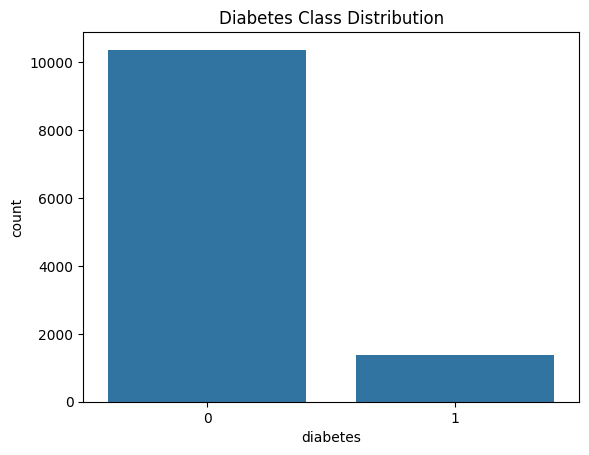

In [233]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='diabetes', data=df_subset)
plt.title("Diabetes Class Distribution")
plt.show()

In [234]:
df_subset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11736 entries, 0 to 11932
Data columns (total 47 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   SEQN                                     11736 non-null  float64
 1   alcohol_use_frequency_last_12m           11736 non-null  float64
 2   bp_high_ever                             11736 non-null  float64
 3   cholesterol_high_ever                    11736 non-null  float64
 4   diabetes                                 11736 non-null  int64  
 5   insurance_covered                        11736 non-null  float64
 6   insurance_private                        11736 non-null  float64
 7   insurance_medicare                       11736 non-null  float64
 8   insurance_medicaid                       11736 non-null  float64
 9   care_delayed_due_to_cost                 11736 non-null  float64
 10  self_rated_health                        11729 non-

In [235]:
df_subset[['cigarette_per_day','cigarettes_per_day','cigarrete_smokedays_last_30days']].describe()

,cigarette_per_day,cigarettes_per_day,cigarrete_smokedays_last_30days
count,11736.000000,1.043100e+04,11736.000000
mean,2.930726,3.217333e-01,2.802488
std,5.702978,6.082103e-01,4.706487
min,0.000000,5.397605e-79,0.000000
25%,0.000000,5.397605e-79,0.000000
50%,0.000000,5.397605e-79,0.000000
75%,5.000000,5.397605e-79,10.000000
max,95.000000,2.000000e+00,30.000000


In [236]:
df_subset.drop(columns='cigarettes_per_day', inplace=True)

In [237]:
df_subset.to_csv("NHANES_subset_step2.csv", index=False)

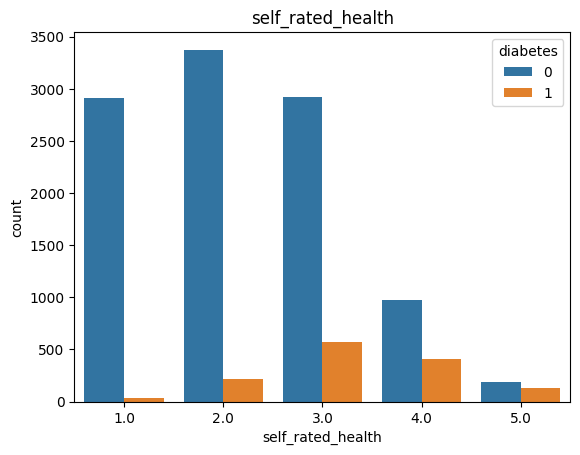

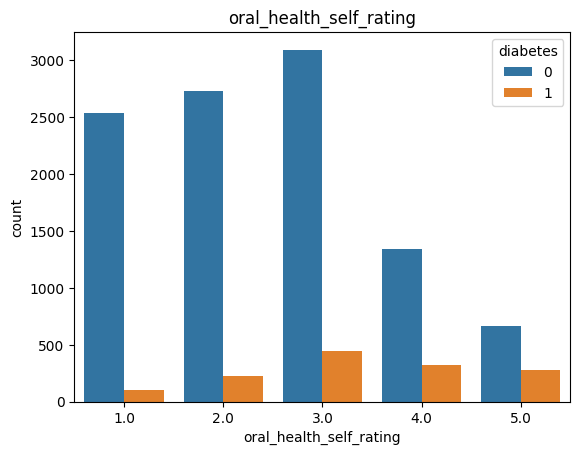

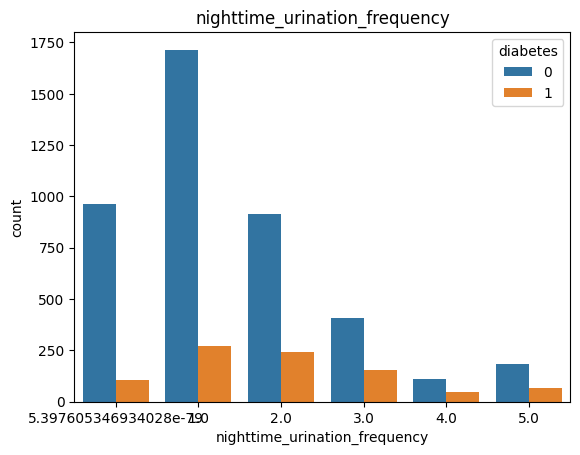

In [238]:
for col in [
    'self_rated_health',
    'oral_health_self_rating',
    'nighttime_urination_frequency'
]:
    sns.countplot(x=col, hue='diabetes', data=df_subset)
    plt.title(col)
    plt.show()


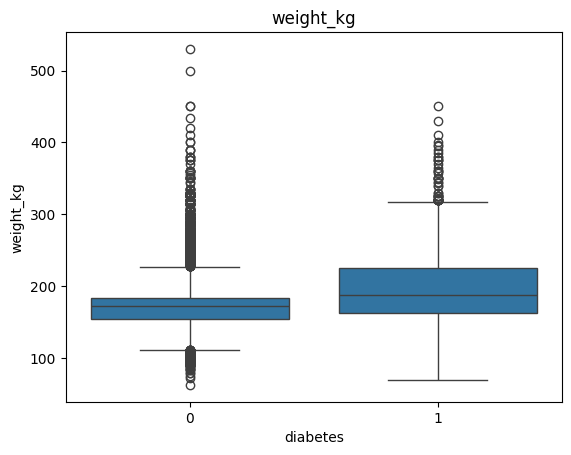

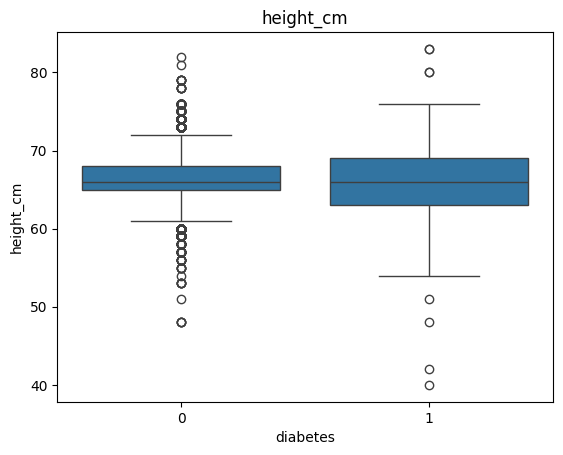

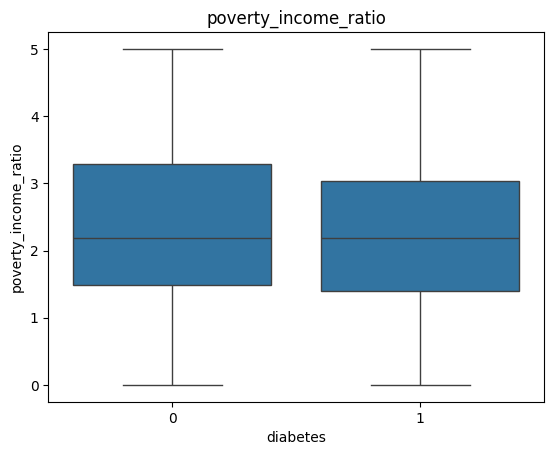

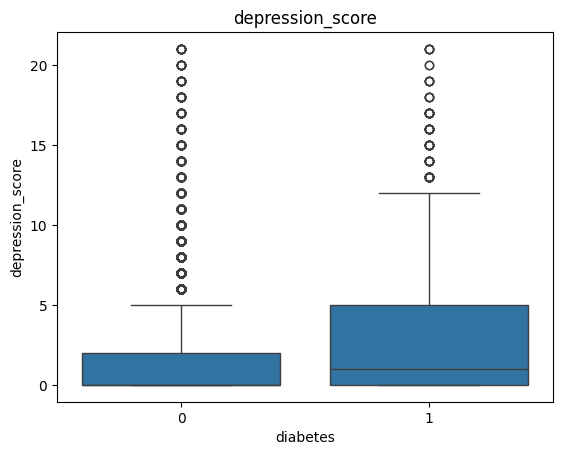

In [240]:
for col in [
    'weight_kg','height_cm','poverty_income_ratio',
    'depression_score'
]:
    sns.boxplot(x='diabetes', y=col, data=df_subset)
    plt.title(col)
    plt.show()


**Outlier Handling**

In [241]:
numeric_cols = df_subset.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    df_subset[col] = np.where(df_subset[col] < 1e-10, 0, df_subset[col])
print("Replaced SAS artifact values (e-79) with 0.")

df_subset['height_cm'] = df_subset['height_cm'] * 2.54 
df_subset['weight_kg'] = df_subset['weight_kg'] * 0.453592
print("Corrected Height/Weight units: Data is now actually in cm and kg.")

# 3. COMPREHENSIVE OUTLIER CAPPING
continuous_cols = [
    'duration_moderate_activity', 'duration_vigorous_activity',
    'sitting_time_per_day', 'cigarette_per_day',
    'height_cm', 'weight_kg', 'poverty_income_ratio', 'depression_score'
]

def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    # Using 3.0 * IQR for a conservative cap (standard for health data)
    upper = Q3 + 3.0 * IQR
    lower = Q1 - 3.0 * IQR
    df[column] = np.where(df[column] > upper, upper, df[column])
    df[column] = np.where(df[column] < lower, lower, df[column])

for col in continuous_cols:
    cap_outliers(df_subset, col)

# 4. FINAL TOUCHES (From your final_columns.txt)
df_subset['total_savings_log'] = np.log1p(df_subset['total_savings'])

df_subset.drop(columns=['SEQN'], inplace=True)
# Save the absolute final version
df_subset.to_csv('NHANES_final.csv', index=False)
print("\n CLEANED FILE READY: 'NHANES_final.csv'")

Replaced SAS artifact values (e-79) with 0.
Corrected Height/Weight units: Data is now actually in cm and kg.

 CLEANED FILE READY: 'NHANES_final.csv'


**EDA**

In [242]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib import ticker

df=pd.read_csv("NHANES_final.csv")

# Shape and types
print("Data shape:", df.shape)
print("\nData types:\n", df.dtypes)

# Summary statistics
print("\nContinuous features summary:\n", df[continuous_features].describe())
print("\nOrdinal features summary:\n", df[ordinal_features].describe())
print("\nBinary features summary:\n", df[binary_features].describe())

# Missing values
missing = df.isnull().sum().sort_values(ascending=False)
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Missing": missing, "Percent": missing_percent})
print("\nMissing values:\n", missing_df[missing_df["Missing"] > 0])

Data shape: (11736, 46)

Data types:
 alcohol_use_frequency_last_12m             float64
bp_high_ever                               float64
cholesterol_high_ever                      float64
diabetes                                     int64
insurance_covered                          float64
insurance_private                          float64
insurance_medicare                         float64
insurance_medicaid                         float64
care_delayed_due_to_cost                   float64
self_rated_health                          float64
usual_place_for_care                       float64
poverty_income_ratio                       float64
total_savings                              float64
nighttime_urination_frequency              float64
oral_health_self_rating                    float64
gum_disease                                float64
mouth_pain                                 float64
difficulty_chewing                         float64
frequency_moderate_activity                f

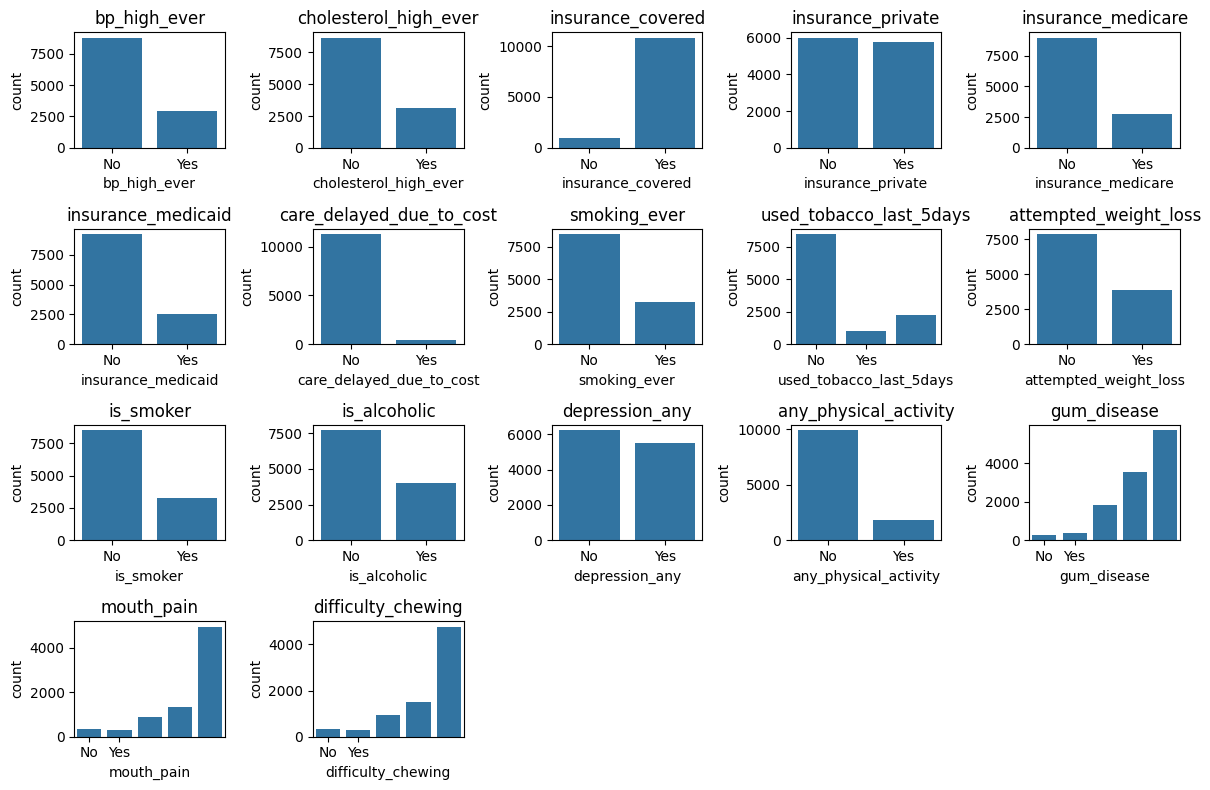

In [243]:
plt.figure(figsize=(12,8))
for i, feature in enumerate(binary_features, 1):
    plt.subplot(4, 5, i)
    sns.countplot(data=df, x=feature)
    plt.title(feature)
    plt.xticks([0,1], ['No', 'Yes'])
plt.tight_layout()
plt.show()

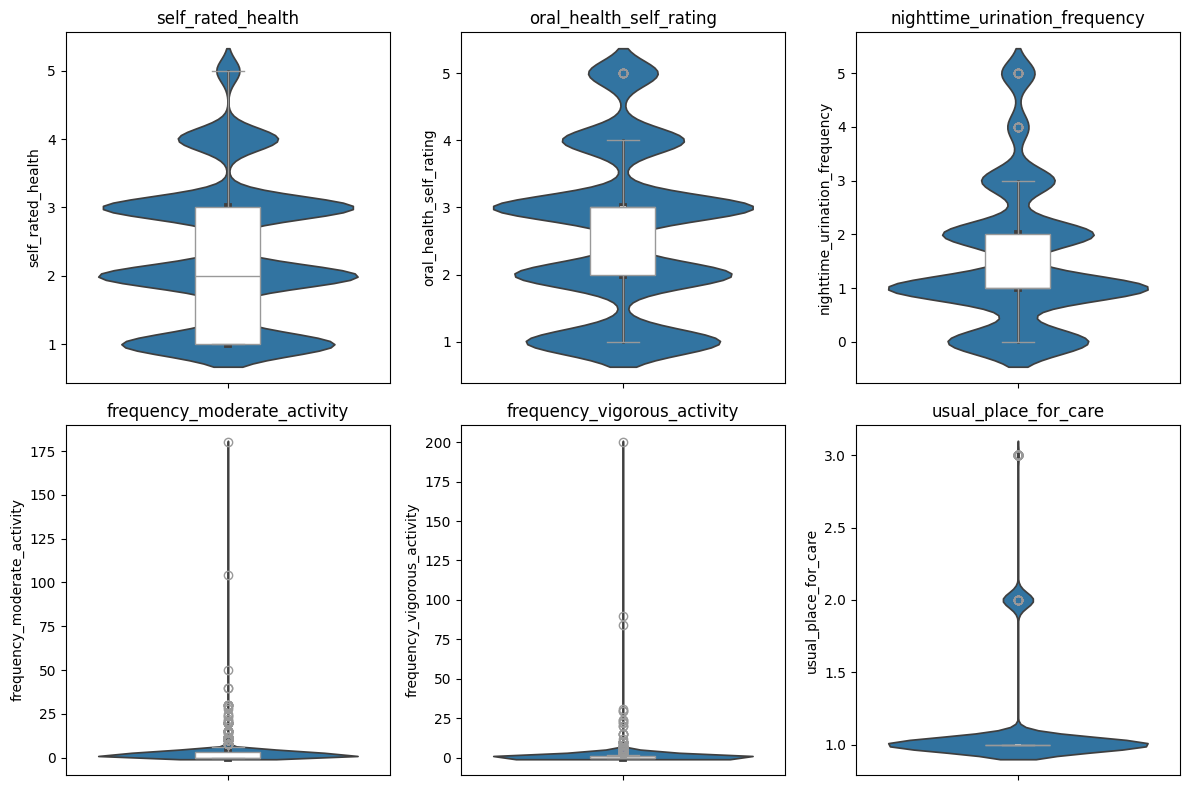

In [244]:
plt.figure(figsize=(12,8))
for i, feature in enumerate(ordinal_features, 1):
    plt.subplot(2, 3, i)
    sns.violinplot(y=df[feature])
    sns.boxplot(y=df[feature], color='white', width=0.2)
    plt.title(feature)
plt.tight_layout()
plt.show()

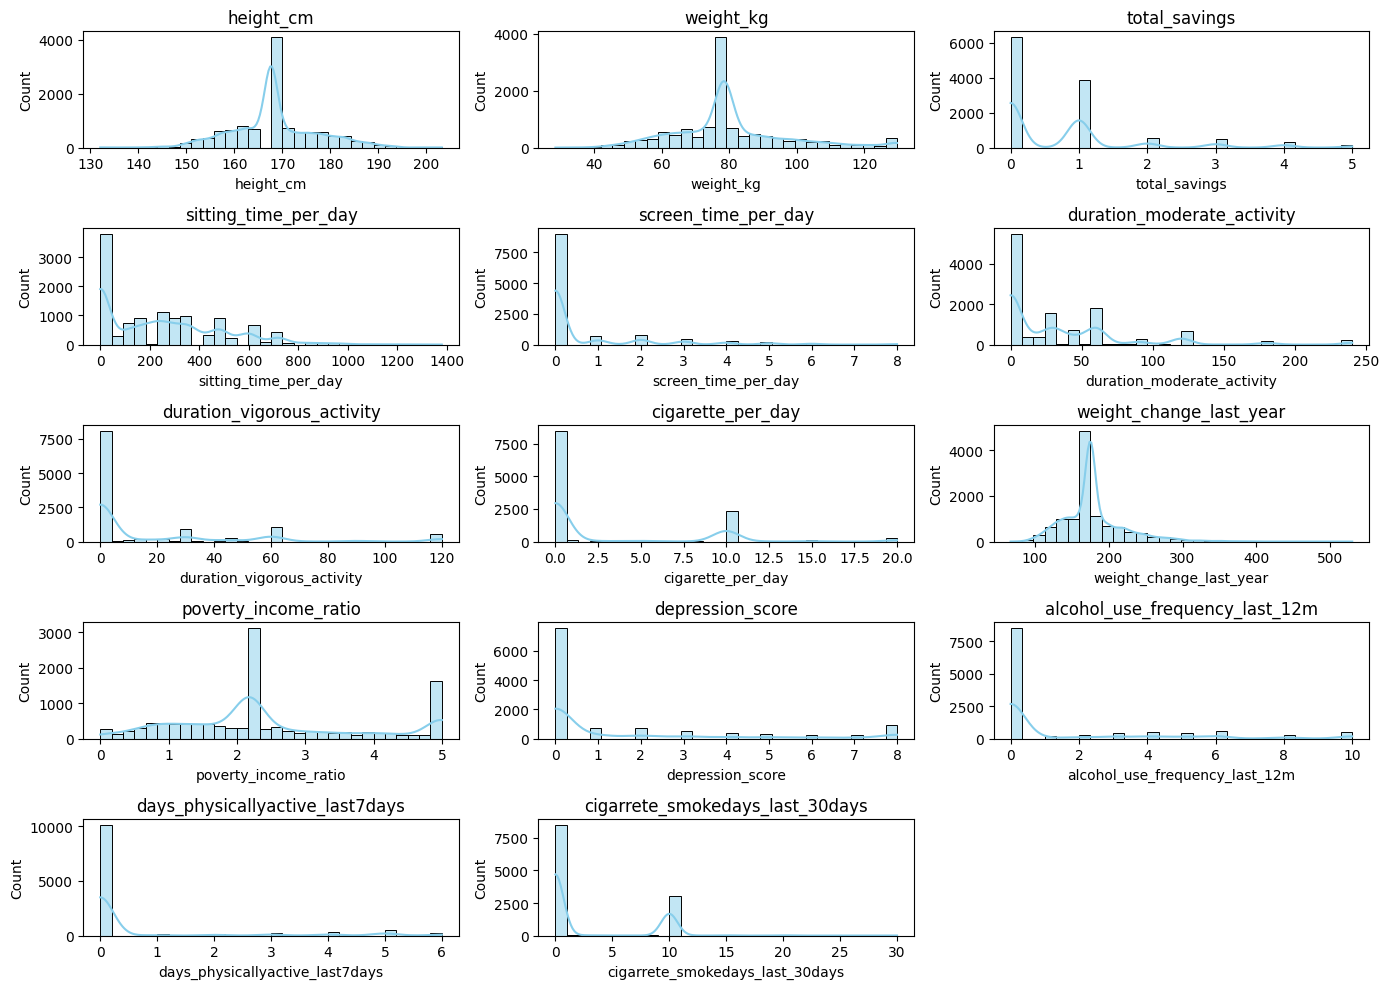

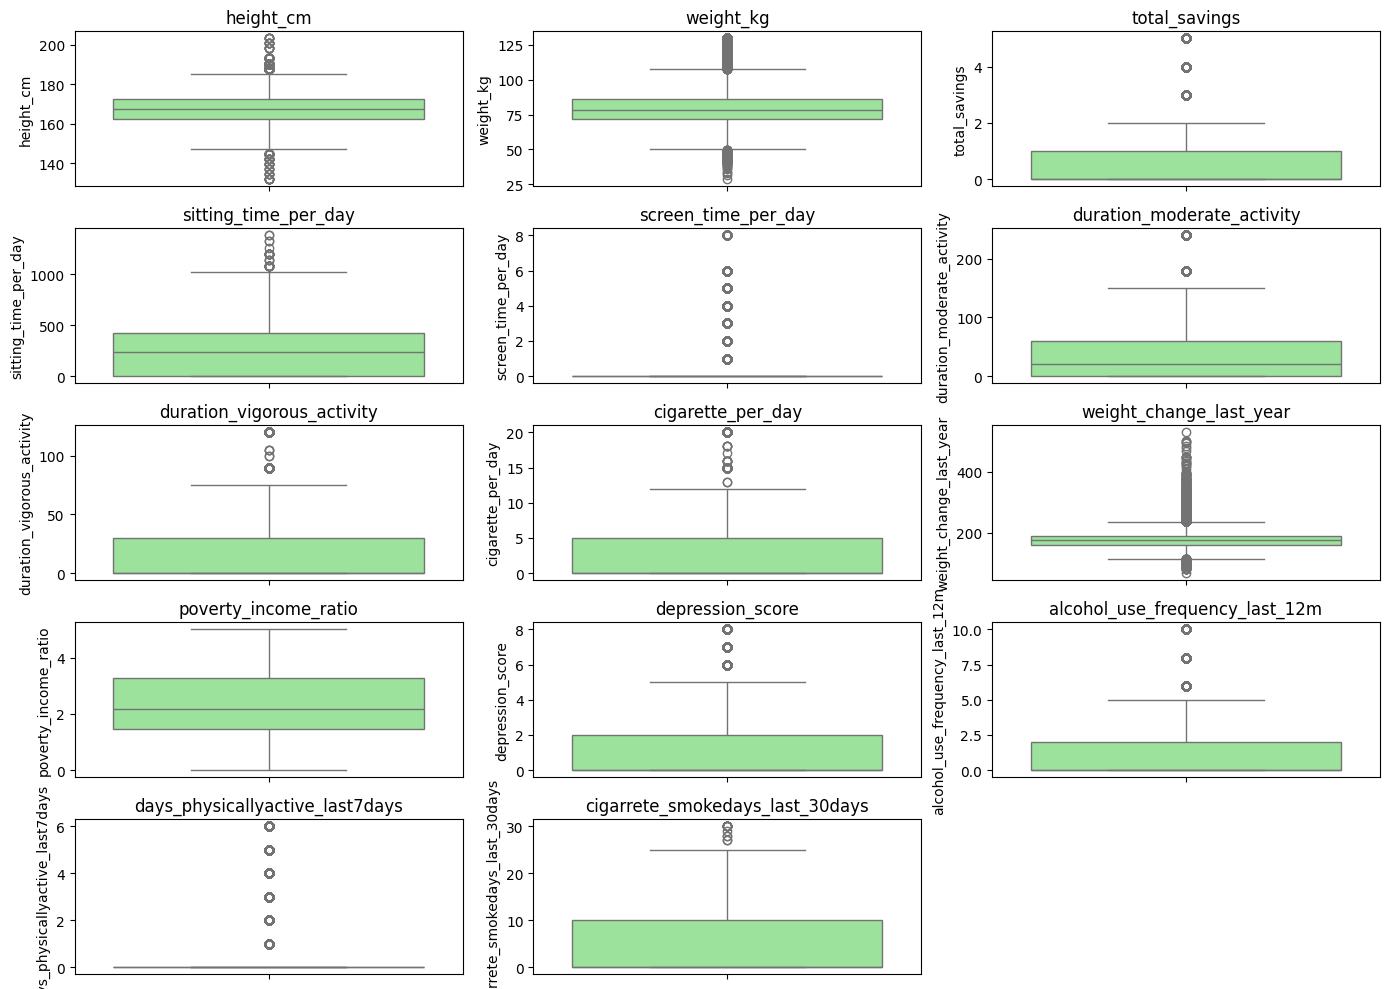

In [245]:
plt.figure(figsize=(14,10))
for i, feature in enumerate(continuous_features, 1):
    plt.subplot(5, 3, i)
    sns.histplot(df[feature], kde=True, bins=30, color='skyblue')
    plt.title(feature)
plt.tight_layout()
plt.show()

# Boxplots for outlier detection
plt.figure(figsize=(14,10))
for i, feature in enumerate(continuous_features, 1):
    plt.subplot(5, 3, i)
    sns.boxplot(y=df[feature], color='lightgreen')
    plt.title(feature)
plt.tight_layout()
plt.show()

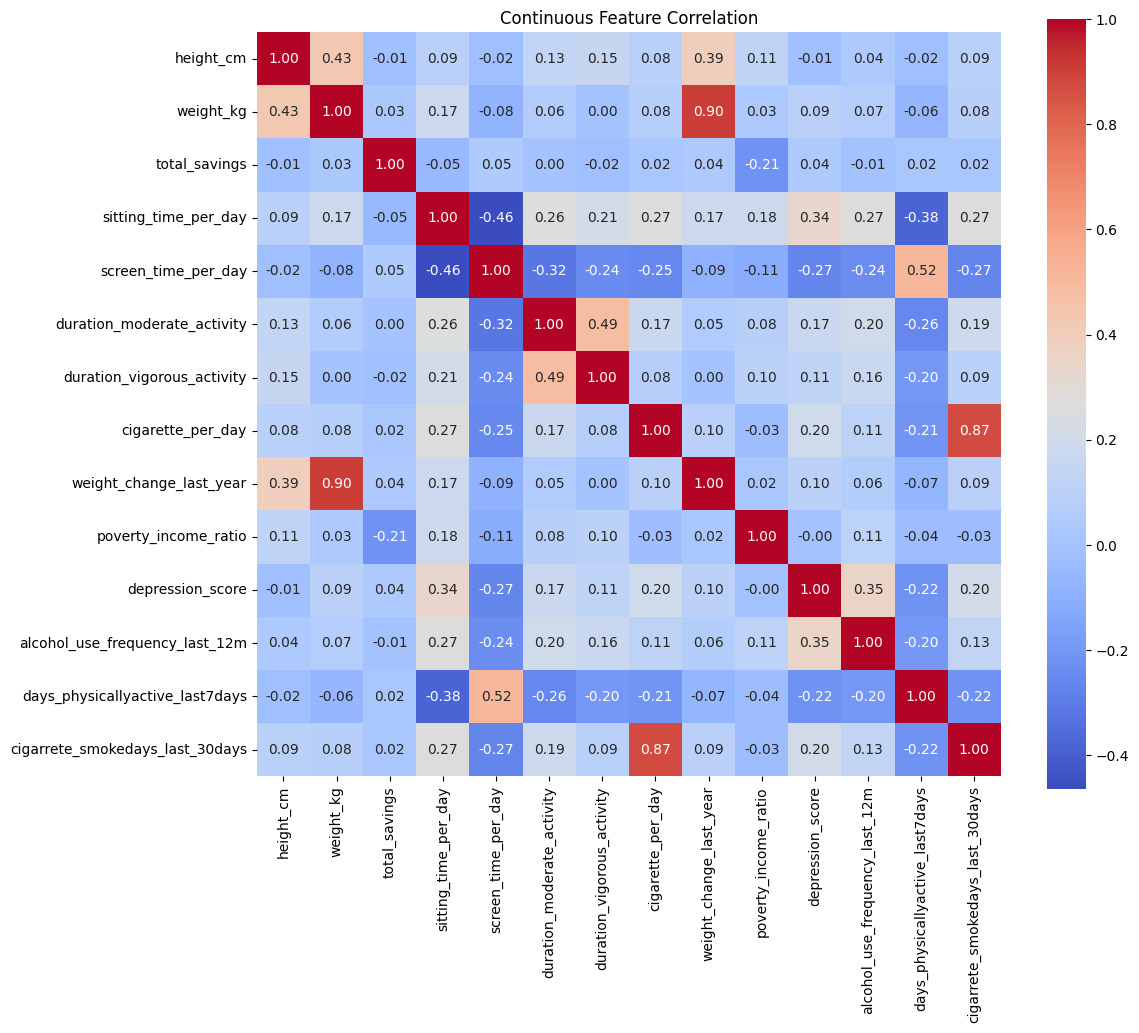

In [246]:
plt.figure(figsize=(12,10))
corr = df[continuous_features].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Continuous Feature Correlation")
plt.show()

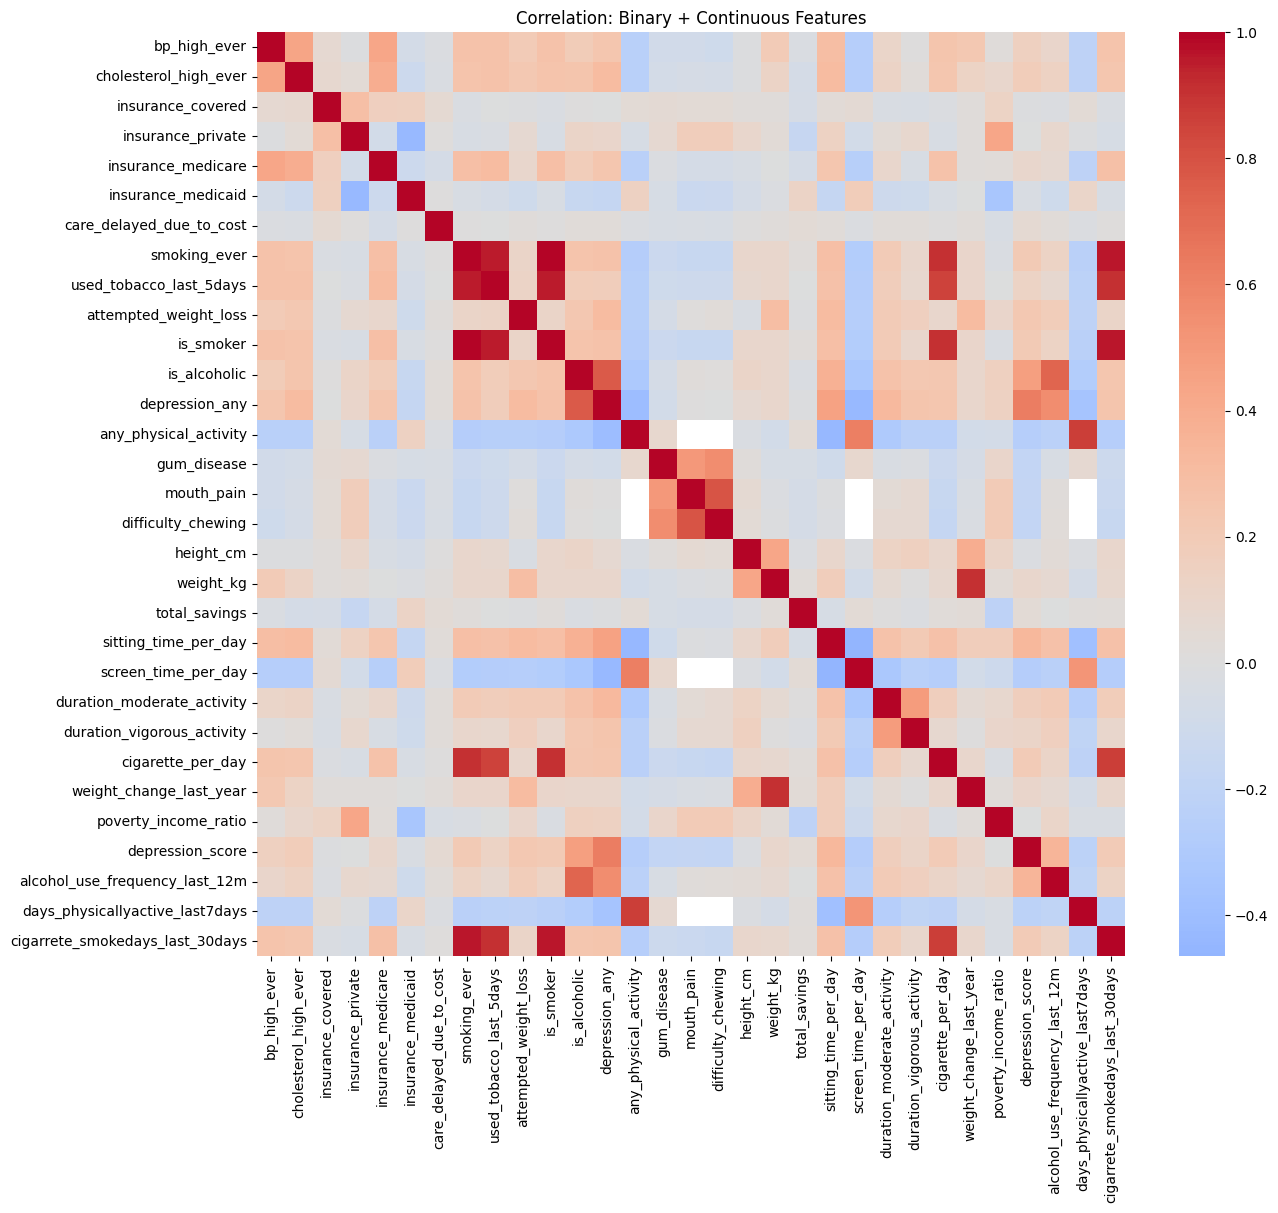

In [247]:
plt.figure(figsize=(14,12))
full_corr = df[binary_features + continuous_features].corr()
sns.heatmap(full_corr, cmap='coolwarm', center=0, annot=False)
plt.title("Correlation: Binary + Continuous Features")
plt.show()

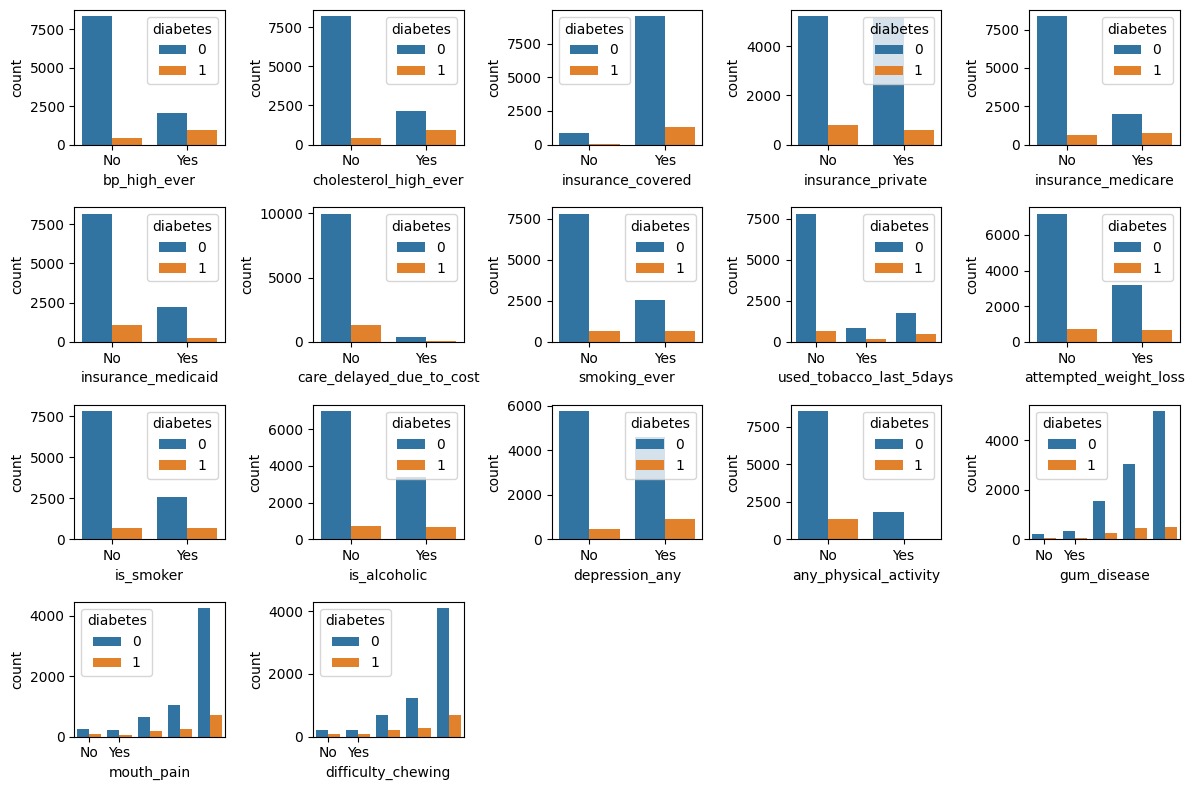

In [248]:
plt.figure(figsize=(12,8))
for i, feature in enumerate(binary_features, 1):
    plt.subplot(4,5,i)
    sns.countplot(x=feature, hue="diabetes", data=df)
    plt.xticks([0,1], ['No', 'Yes'])
plt.tight_layout()
plt.show()

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_9244\3849140038.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="diabetes", y=feature, data=df, split=True, palette="Set2")
C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_9244\3849140038.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="diabetes", y=feature, data=df, split=True, palette="Set2")
C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_9244\3849140038.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="diabetes", y=feature, data=df, split=True, palette="Set2")
C:\Users\Bhoo

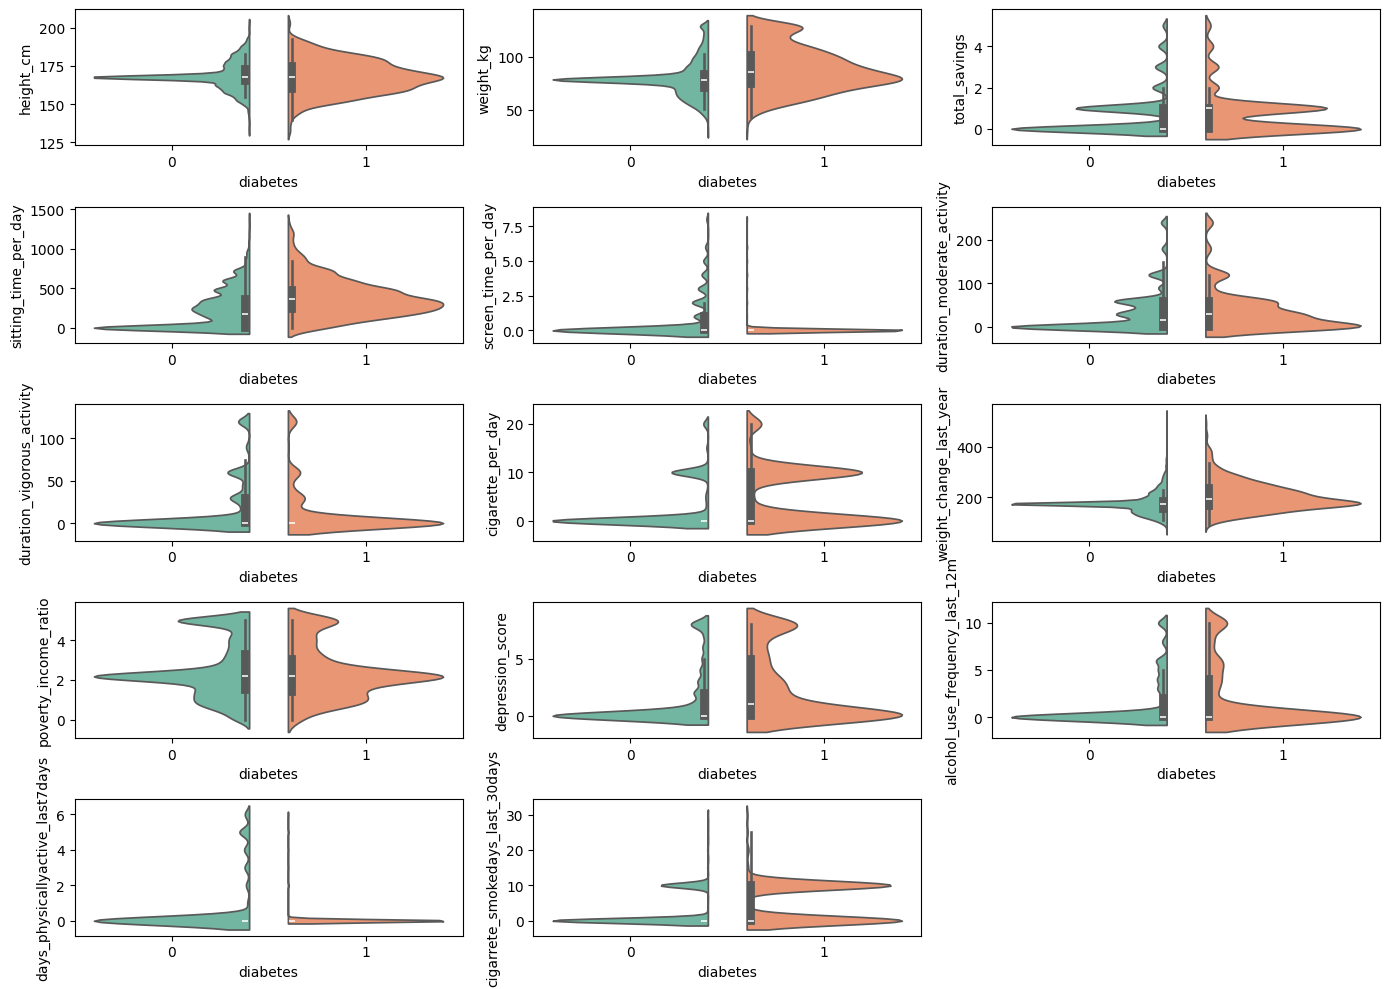

In [249]:
plt.figure(figsize=(14,10))
for i, feature in enumerate(continuous_features, 1):
    plt.subplot(5,3,i)
    sns.violinplot(x="diabetes", y=feature, data=df, split=True, palette="Set2")
plt.tight_layout()
plt.show()

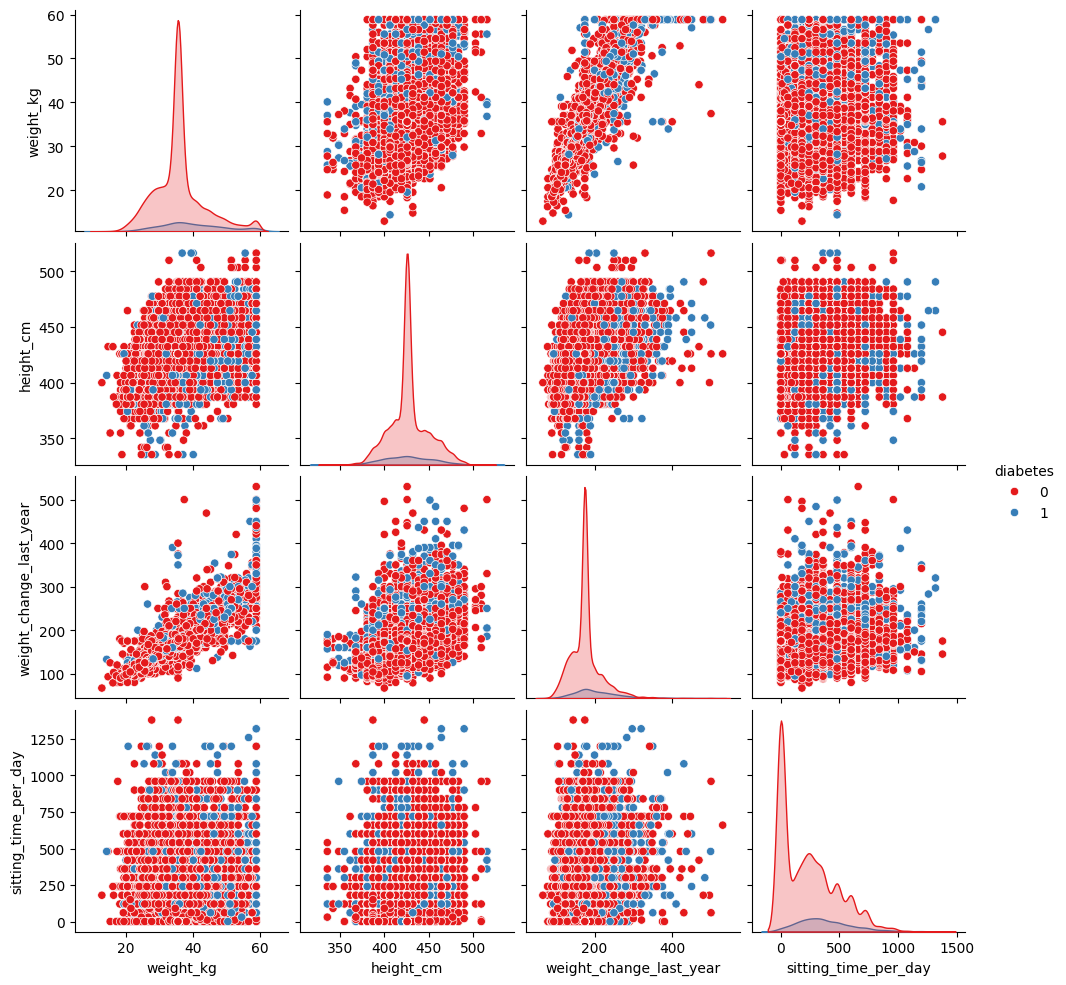

In [ ]:
top_continuous = ['weight_kg', 'height_cm', 'weight_change_last_year', 'sitting_time_per_day']
sns.pairplot(df, vars=top_continuous, hue="diabetes", palette="Set1")
plt.show()

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_9244\2149475360.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_target.index, y=corr_target.values, palette="viridis")


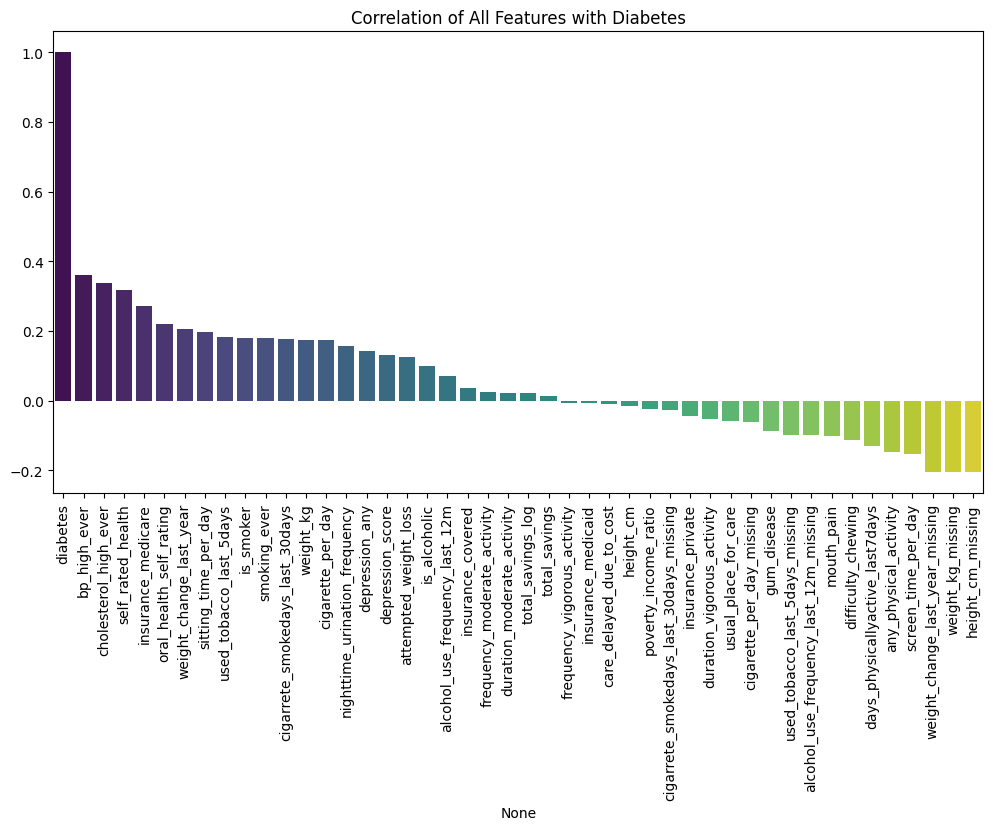

In [250]:
plt.figure(figsize=(12,6))
corr_target = df.corr()["diabetes"].sort_values(ascending=False)
sns.barplot(x=corr_target.index, y=corr_target.values, palette="viridis")
plt.xticks(rotation=90)
plt.title("Correlation of All Features with Diabetes")
plt.show()

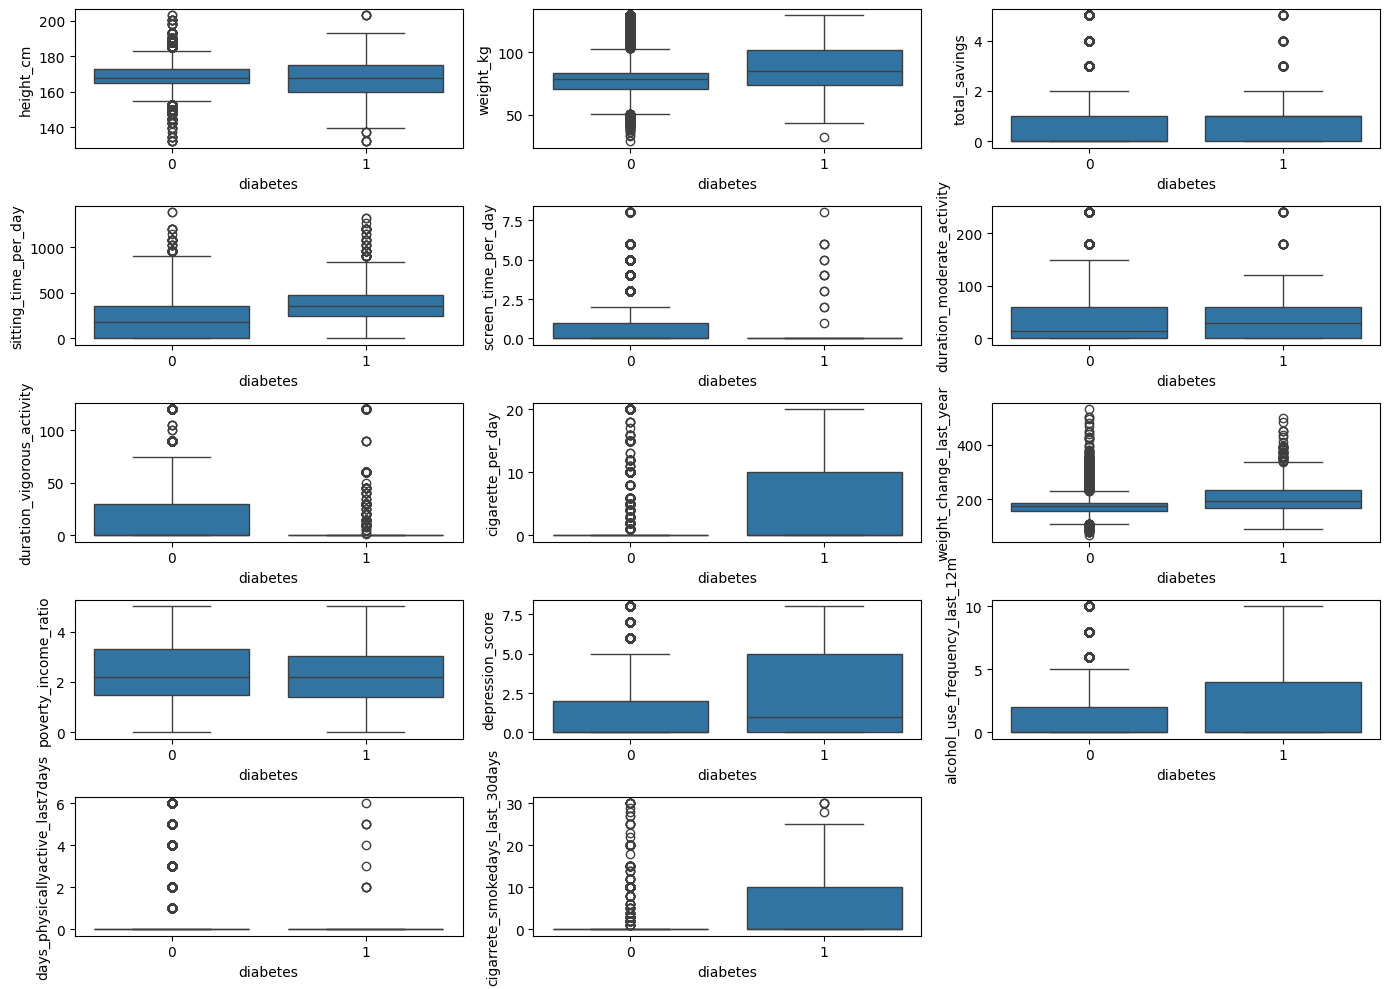

In [251]:
plt.figure(figsize=(14,10))
for i, feature in enumerate(continuous_features, 1):
    plt.subplot(5,3,i)
    sns.boxplot(x="diabetes", y=feature, data=df)
plt.tight_layout()
plt.show()

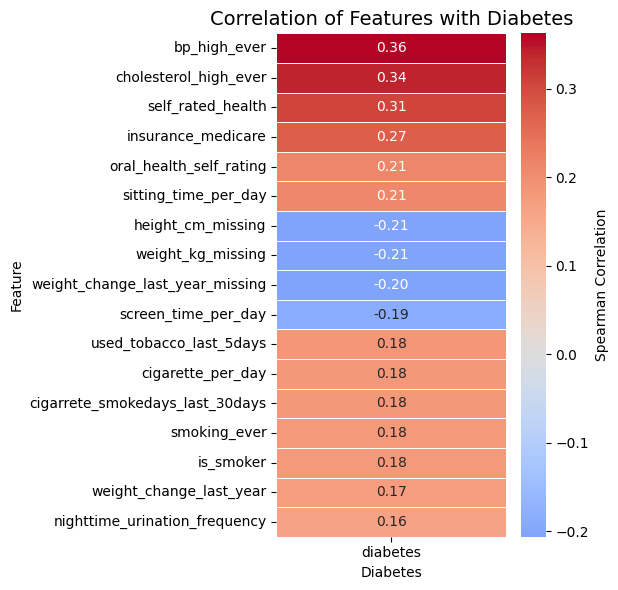

In [252]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("NHANES_final.csv")

numeric_df = df.select_dtypes(include=[np.number])

corr = numeric_df.corr(method="spearman")

target = "diabetes"

diabetes_corr = (
    corr[target]
    .drop(target)
    .dropna()
    .sort_values(key=np.abs, ascending=False)
)

corr_threshold = 0.15
important_corr = diabetes_corr[diabetes_corr.abs() >= corr_threshold]

plt.figure(figsize=(6, max(6, 0.35 * len(important_corr))))

sns.heatmap(
    important_corr.to_frame(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Spearman Correlation"}
)

plt.title("Correlation of Features with Diabetes", fontsize=14)
plt.ylabel("Feature")
plt.xlabel("Diabetes")
plt.tight_layout()
plt.savefig("diabetes_correlation_heatmap.png", dpi=300)
plt.show()

**Logistic Reression**

In [266]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, classification_report, recall_score


X = df_subset.drop(columns=["diabetes"])
y = df_subset["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['bp_high_ever',
                                                   'cholesterol_high_ever',
                                                   'insurance_covered',
                                                   'insurance_private',
                                                   'insurance_medicare',
                                                   'insurance_medicaid',
                                                   'care_delayed_due_to_cost',
                                                   'smoking_ever',
                                                   'used_tobacco_last_5days',
                                                   'attempted_weigh...
                                                   'sitting_time_per_day',
                                                   'screen_time_per_day',
                                                   'duration_moderate_activity',
                                                   'duration_vigorous_activity',
                                                   'cigarette_per_day',
                                                   'weight_change_last_year',
                                                   'poverty_income_ratio',
                                                   'depression_score',
                                                   'alcohol_use_frequency_last_12m',
                                                   'days_physicallyactive_last7days',
                                                   'cigarrete_smokedays_last_30days'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [254]:
classifier = model.named_steps['classifier']
feature_names = model.named_steps['preprocessor'].get_feature_names_out(X_train.columns)

# Step 3: Get weights
weights = classifier.coef_[0]

# Step 4: Print
for name, coef in zip(feature_names, weights):
    print(f"{name}: {coef:.4f}")
y_prob = model.predict_proba(X_test)[:,1]
threshold = 0.49  # try 0.6, 0.7, etc
y_pred_thresh = (y_prob >= threshold).astype(int)


print("\nAccuracy:", accuracy_score(y_test, y_pred_thresh))
print("Recall:", recall_score(y_test, y_pred_thresh))  # explicit recall
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_thresh))
print("\nClassification Report:\n", classification_report(y_test, y_pred_thresh))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob))

binary__bp_high_ever: 0.8698
binary__cholesterol_high_ever: 1.1323
binary__insurance_covered: 0.1961
binary__insurance_private: -0.1455
binary__insurance_medicare: 0.2763
binary__insurance_medicaid: 0.0131
binary__care_delayed_due_to_cost: -0.3452
binary__smoking_ever: -0.1650
binary__used_tobacco_last_5days: 0.1159
binary__attempted_weight_loss: -0.0317
binary__is_smoker: -0.1650
binary__is_alcoholic: -0.3439
binary__depression_any: 0.2596
binary__any_physical_activity: -0.1428
binary__gum_disease: 0.0385
binary__mouth_pain: -0.0002
binary__difficulty_chewing: 0.0093
ordinal__self_rated_health: 0.6170
ordinal__oral_health_self_rating: 0.1810
ordinal__nighttime_urination_frequency: 0.1080
ordinal__frequency_moderate_activity: 0.0038
ordinal__frequency_vigorous_activity: 0.0085
ordinal__usual_place_for_care: -0.3674
continuous__height_cm: -0.1284
continuous__weight_kg: -0.0639
continuous__total_savings: 0.0726
continuous__sitting_time_per_day: 0.1521
continuous__screen_time_per_day: -0.

**KNN**

In [255]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", KNeighborsClassifier(
        n_neighbors=15,
        weights='distance',
    ))
])

knn_pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['bp_high_ever',
                                                   'cholesterol_high_ever',
                                                   'insurance_covered',
                                                   'insurance_private',
                                                   'insurance_medicare',
                                                   'insurance_medicaid',
                                                   'care_delayed_due_to_cost',
                                                   'smoking_ever',
                                                   'used_tobacco_last_5days',
                                                   'attempted_weigh...
                                                   'duration_moderate_activity',
                                                   'duration_vigorous_activity',
                                                   'cigarette_per_day',
                                                   'weight_change_last_year',
                                                   'poverty_income_ratio',
                                                   'depression_score',
                                                   'alcohol_use_frequency_last_12m',
                                                   'days_physicallyactive_last7days',
                                                   'cigarrete_smokedays_last_30days'])])),
                ('smote', SMOTE(random_state=42)),
                ('classifier',
                 KNeighborsClassifier(n_neighbors=15, weights='distance'))])

In [256]:
y_pred = knn_pipeline.predict(X_test)
y_prob = knn_pipeline.predict_proba(X_test)[:,1]

# Metrics
from sklearn.metrics import classification_report, confusion_matrix, recall_score, accuracy_score, roc_auc_score
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall (diabetes):", recall_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.6652470187393527
Recall (diabetes): 0.8241758241758241
Confusion Matrix:
 [[1337  738]
 [  48  225]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.64      0.77      2075
           1       0.23      0.82      0.36       273

    accuracy                           0.67      2348
   macro avg       0.60      0.73      0.57      2348
weighted avg       0.88      0.67      0.73      2348

ROC AUC: 0.8002939229445254


**SVM**

In [257]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, classification_report, roc_auc_score

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),  # your ColumnTransformer
    ("classifier", SVC(
        kernel='rbf',           # radial basis function kernel
        C=1.0,                  # regularization parameter
        class_weight='balanced',# handle imbalanced classes
        probability=True,       # needed for predict_proba and ROC AUC
        random_state=42
    ))
])

# Train
svm_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['bp_high_ever',
                                                   'cholesterol_high_ever',
                                                   'insurance_covered',
                                                   'insurance_private',
                                                   'insurance_medicare',
                                                   'insurance_medicaid',
                                                   'care_delayed_due_to_cost',
                                                   'smoking_ever',
                                                   'used_tobacco_last_5days',
                                                   'attempted_weigh...
                                                   'screen_time_per_day',
                                                   'duration_moderate_activity',
                                                   'duration_vigorous_activity',
                                                   'cigarette_per_day',
                                                   'weight_change_last_year',
                                                   'poverty_income_ratio',
                                                   'depression_score',
                                                   'alcohol_use_frequency_last_12m',
                                                   'days_physicallyactive_last7days',
                                                   'cigarrete_smokedays_last_30days'])])),
                ('classifier',
                 SVC(class_weight='balanced', probability=True,
                     random_state=42))])

In [258]:
# Predictions
y_pred = svm_pipeline.predict(X_test)
y_prob = svm_pipeline.predict_proba(X_test)[:,1]

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall (diabetes):", recall_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob))

Accuracy: 0.7597955706984668
Recall (diabetes): 0.8388278388278388
Confusion Matrix:
 [[1555  520]
 [  44  229]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.75      0.85      2075
           1       0.31      0.84      0.45       273

    accuracy                           0.76      2348
   macro avg       0.64      0.79      0.65      2348
weighted avg       0.89      0.76      0.80      2348

ROC AUC Score: 0.8653762301955072


**Decision Tree**

In [259]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, classification_report, roc_auc_score
import numpy as np

# 1. Pipeline with SMOTE + Decision Tree
dt_smote_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),   # your existing ColumnTransformer
    ("smote", SMOTE(random_state=42)), # generate synthetic diabetes samples
    ("classifier", DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

# 2. Hyperparameter grid for tuning
param_grid = {
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10],
}

# 3. GridSearchCV optimizing recall for diabetes (minority class)
grid_dt = GridSearchCV(dt_smote_pipeline, param_grid, scoring='recall', cv=5)
grid_dt.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('binary',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent'))]),
                                                                         ['bp_high_ever',
                                                                          'cholesterol_high_ever',
                                                                          'insurance_covered',
                                                                          'insurance_private',
                                                                          'insurance_medicare',
                                                                          'insurance_medicaid',
                                                                          'care_delayed_due_to_cost',
                                                                          'smoking_ever',
                                                                          'used_tobacco_...
                                                                          'alcohol_use_frequency_last_12m',
                                                                          'days_physicallyactive_last7days',
                                                                          'cigarrete_smokedays_last_30days'])])),
                                       ('smote', SMOTE(random_state=42)),
                                       ('classifier',
                                        DecisionTreeClassifier(class_weight='balanced',
                                                               random_state=42))]),
             param_grid={'classifier__max_depth': [5, 10, 15, None],
                         'classifier__min_samples_leaf': [1, 5, 10],
                         'classifier__min_samples_split': [2, 10, 20]},
             scoring='recall')

In [ ]:
print("Best parameters:", grid_dt.best_params_)

# 4. Predictions
y_prob = grid_dt.best_estimator_.predict_proba(X_test)[:,1]

# 5. Threshold adjustment (optional: lower threshold to boost recall)
threshold = 0.1
y_pred = (y_prob >= threshold).astype(int)

# 6. Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall (diabetes):", recall_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob))


Best parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}
Accuracy: 0.7474446337308348
Recall (diabetes): 0.73992673992674
Confusion Matrix:
 [[1553  522]
 [  71  202]]

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.75      0.84      2075
           1       0.28      0.74      0.41       273

    accuracy                           0.75      2348
   macro avg       0.62      0.74      0.62      2348
weighted avg       0.88      0.75      0.79      2348

ROC AUC Score: 0.8123359371552142


**Random Forest**

In [262]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, classification_report, roc_auc_score
import numpy as np

# 1. Pipeline: Preprocessing + SMOTE + Random Forest
rf_smote_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),     # your existing ColumnTransformer
    ("smote", SMOTE(random_state=42)), # generate synthetic diabetes samples
    ("classifier", RandomForestClassifier(
        class_weight='balanced', 
        n_jobs=-1, 
        random_state=42
    ))
])

# 2. Hyperparameter grid for tuning
param_grid = {
    "classifier__n_estimators": [100, 200],       # number of trees
    "classifier__max_depth": [10, 20, None],     # max depth of each tree
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10],
    "classifier__max_features": ["sqrt", "log2", None]
}

# 3. GridSearchCV optimizing recall for diabetes
grid_rf = GridSearchCV(rf_smote_pipeline, param_grid, scoring='recall', cv=5, verbose=1)
grid_rf.fit(X_train, y_train)


Fitting 5 folds for each of 162 candidates, totalling 810 fits


c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\ma\core.py:2885: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('binary',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent'))]),
                                                                         ['bp_high_ever',
                                                                          'cholesterol_high_ever',
                                                                          'insurance_covered',
                                                                          'insurance_private',
                                                                          'insurance_medicare',
                                                                          'insurance_medicaid',
                                                                          'care_delayed_due_to_cost',
                                                                          'smoking_ever',
                                                                          'used_tobacco_...
                                       ('smote', SMOTE(random_state=42)),
                                       ('classifier',
                                        RandomForestClassifier(class_weight='balanced',
                                                               n_jobs=-1,
                                                               random_state=42))]),
             param_grid={'classifier__max_depth': [10, 20, None],
                         'classifier__max_features': ['sqrt', 'log2', None],
                         'classifier__min_samples_leaf': [1, 5, 10],
                         'classifier__min_samples_split': [2, 10, 20],
                         'classifier__n_estimators': [100, 200]},
             scoring='recall', verbose=1)

In [263]:
print("Best parameters:", grid_rf.best_params_)

# 4. Predictions
y_prob = grid_rf.best_estimator_.predict_proba(X_test)[:,1]

# 5. Threshold adjustment (optional)
threshold = 0.22  # lower to increase recall if needed
y_pred = (y_prob >= threshold).astype(int)

# 6. Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall (diabetes):", recall_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob))

Best parameters: {'classifier__max_depth': 10, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Accuracy: 0.7201873935264055
Recall (diabetes): 0.8827838827838828
Confusion Matrix:
 [[1450  625]
 [  32  241]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.70      0.82      2075
           1       0.28      0.88      0.42       273

    accuracy                           0.72      2348
   macro avg       0.63      0.79      0.62      2348
weighted avg       0.90      0.72      0.77      2348

ROC AUC Score: 0.8645077011342072


**XGB**

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, classification_report, roc_auc_score

# 1. Pipeline: Preprocessing + SMOTE + XGBoost
xgb_smote_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),     # your existing ColumnTransformer
    ("smote", SMOTE(random_state=42)), # generate synthetic diabetes samples
    ("classifier", XGBClassifier(
        use_label_encoder=False,
        eval_metric='logloss',
        n_jobs=-1,
        random_state=42
    ))
])

# 2. Hyperparameter grid for tuning
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5, 7],
    "classifier__learning_rate": [0.01, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0]
}

# 3. GridSearchCV optimizing recall for diabetes
grid_xgb = GridSearchCV(xgb_smote_pipeline, param_grid, scoring='roc_auc', cv=5, verbose=1)
grid_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 162 candidates, totalling 810 fits


c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [06:11:54] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [06:11:54] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [06:11:54] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [06:11:55] WARNING: C:\a

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('binary',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent'))]),
                                                                         ['bp_high_ever',
                                                                          'cholesterol_high_ever',
                                                                          'insurance_covered',
                                                                          'insurance_private',
                                                                          'insurance_medicare',
                                                                          'insurance_medicaid',
                                                                          'care_delayed_due_to_cost',
                                                                          'smoking_ever',
                                                                          'used_tobacco_...
                                                      missing=nan,
                                                      monotone_constraints=None,
                                                      multi_strategy=None,
                                                      n_estimators=None,
                                                      n_jobs=-1,
                                                      num_parallel_tree=None, ...))]),
             param_grid={'classifier__colsample_bytree': [0.7, 0.8, 1.0],
                         'classifier__learning_rate': [0.01, 0.05, 0.1],
                         'classifier__max_depth': [3, 5, 7],
                         'classifier__n_estimators': [100, 200],
                         'classifier__subsample': [0.7, 0.8, 1.0]},
             scoring='roc_auc', verbose=1)

In [ ]:
print("Best parameters:", grid_xgb.best_params_)

# 4. Predictions
y_prob = grid_xgb.best_estimator_.predict_proba(X_test)[:,1]

# 5. Threshold adjustment (optional)
threshold = 0.12  # lower threshold to increase recall
y_pred = (y_prob >= threshold).astype(int)

# 6. Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall (diabetes):", recall_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob))


Best parameters: {'classifier__colsample_bytree': 0.7, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__n_estimators': 100, 'classifier__subsample': 0.7}
Accuracy: 0.7163543441226575
Recall (diabetes): 0.8827838827838828
Confusion Matrix:
 [[1441  634]
 [  32  241]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.69      0.81      2075
           1       0.28      0.88      0.42       273

    accuracy                           0.72      2348
   macro avg       0.63      0.79      0.62      2348
weighted avg       0.90      0.72      0.77      2348

ROC AUC Score: 0.863016020124454


**Neural network**

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, classification_report, roc_auc_score

# 1. Pipeline: Preprocessing + SMOTE + MLP
nn_smote_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),     # your ColumnTransformer
    ("smote", SMOTE(random_state=42)), # generate synthetic diabetes samples
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),    # two hidden layers with 64 and 32 neurons
        activation='relu',
        solver='adam',
        max_iter=500,
        random_state=42
    ))
])

# 2. Hyperparameter grid
param_grid = {
    "classifier__hidden_layer_sizes": [(64, 32), (128, 64), (32, 16)],
    "classifier__activation": ['relu', 'tanh'],
    "classifier__alpha": [0.0001, 0.001, 0.01],  # L2 regularization
}

# 3. GridSearchCV optimizing recall
grid_nn = GridSearchCV(nn_smote_pipeline, param_grid, scoring='recall', cv=5, verbose=1)
grid_nn.fit(X_train, y_train)


Fitting 5 folds for each of 18 candidates, totalling 90 fits


c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the 

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('binary',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent'))]),
                                                                         ['bp_high_ever',
                                                                          'cholesterol_high_ever',
                                                                          'insurance_covered',
                                                                          'insurance_private',
                                                                          'insurance_medicare',
                                                                          'insurance_medicaid',
                                                                          'care_delayed_due_to_cost',
                                                                          'smoking_ever',
                                                                          'used_tobacco_...
                                                                          'days_physicallyactive_last7days',
                                                                          'cigarrete_smokedays_last_30days'])])),
                                       ('smote', SMOTE(random_state=42)),
                                       ('classifier',
                                        MLPClassifier(hidden_layer_sizes=(64,
                                                                          32),
                                                      max_iter=500,
                                                      random_state=42))]),
             param_grid={'classifier__activation': ['relu', 'tanh'],
                         'classifier__alpha': [0.0001, 0.001, 0.01],
                         'classifier__hidden_layer_sizes': [(64, 32), (128, 64),
                                                            (32, 16)]},
             scoring='recall', verbose=1)

In [ ]:
print("Best parameters:", grid_nn.best_params_)

# 4. Predictions
y_prob = grid_nn.best_estimator_.predict_proba(X_test)[:,1]

# 5. Threshold adjustment (optional)
threshold = 0.1  # lower threshold to boost recall
y_pred = (y_prob >= threshold).astype(int)

# 6. Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall (diabetes):", recall_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob))

Best parameters: {'classifier__activation': 'relu', 'classifier__alpha': 0.001, 'classifier__hidden_layer_sizes': (32, 16)}
Accuracy: 0.7666098807495741
Recall (diabetes): 0.6117216117216118
Confusion Matrix:
 [[1633  442]
 [ 106  167]]

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.79      0.86      2075
           1       0.27      0.61      0.38       273

    accuracy                           0.77      2348
   macro avg       0.61      0.70      0.62      2348
weighted avg       0.86      0.77      0.80      2348

ROC AUC Score: 0.7873833796725362


**Comparing these models by ROC AUC and Recall**

In [268]:
from sklearn.metrics import (
    roc_auc_score,
    precision_recall_curve,
    auc,
    classification_report,
)
import matplotlib.pyplot as plt
import pandas as pd

models = {
    "Logistic": model,
    "KNN": knn_pipeline,
    "SVM": svm_pipeline,
    "Decision Tree": grid_dt.best_estimator_,
    "Random Forest": grid_rf.best_estimator_,
    "XGBoost": grid_xgb.best_estimator_,
    "Neural Net": grid_nn.best_estimator_
}

results = {}

In [273]:
print(X_test.columns.tolist())

['alcohol_use_frequency_last_12m', 'bp_high_ever', 'cholesterol_high_ever', 'insurance_covered', 'insurance_private', 'insurance_medicare', 'insurance_medicaid', 'care_delayed_due_to_cost', 'self_rated_health', 'usual_place_for_care', 'poverty_income_ratio', 'total_savings', 'nighttime_urination_frequency', 'oral_health_self_rating', 'gum_disease', 'mouth_pain', 'difficulty_chewing', 'frequency_moderate_activity', 'duration_moderate_activity', 'frequency_vigorous_activity', 'duration_vigorous_activity', 'sitting_time_per_day', 'days_physicallyactive_last7days', 'screen_time_per_day', 'smoking_ever', 'cigarrete_smokedays_last_30days', 'cigarette_per_day', 'used_tobacco_last_5days', 'height_cm', 'weight_kg', 'weight_change_last_year', 'attempted_weight_loss', 'is_smoker', 'cigarrete_smokedays_last_30days_missing', 'used_tobacco_last_5days_missing', 'cigarette_per_day_missing', 'is_alcoholic', 'alcohol_use_frequency_last_12m_missing', 'depression_score', 'depression_any', 'any_physical_ac

In [271]:
for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)

    roc_auc = roc_auc_score(y_test, y_prob)

    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(recall, precision)

    report = classification_report(y_test, y_pred, output_dict=True)

    results[name] = {
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "Recall_1": report["1"]["recall"],
        "Precision_1": report["1"]["precision"],
        "F1_1": report["1"]["f1-score"]
    }


ValueError: columns are missing: {'years_smoked'}

In [ ]:
comparison_df = pd.DataFrame(results).T.sort_values("PR_AUC", ascending=False)
print(comparison_df)

                ROC_AUC    PR_AUC  Recall_1  Precision_1      F1_1
SVM            0.865450  0.453886  0.838828     0.305741  0.448141
Logistic       0.862569  0.446688  0.813187     0.314003  0.453061
Random Forest  0.863254  0.427930  0.556777     0.400000  0.465544
XGBoost        0.863016  0.425137  0.461538     0.482759  0.471910
Decision Tree  0.816491  0.377736  0.512821     0.406977  0.453809
KNN            0.800294  0.343158  0.824176     0.233645  0.364078
Neural Net     0.787383  0.298854  0.476190     0.311751  0.376812


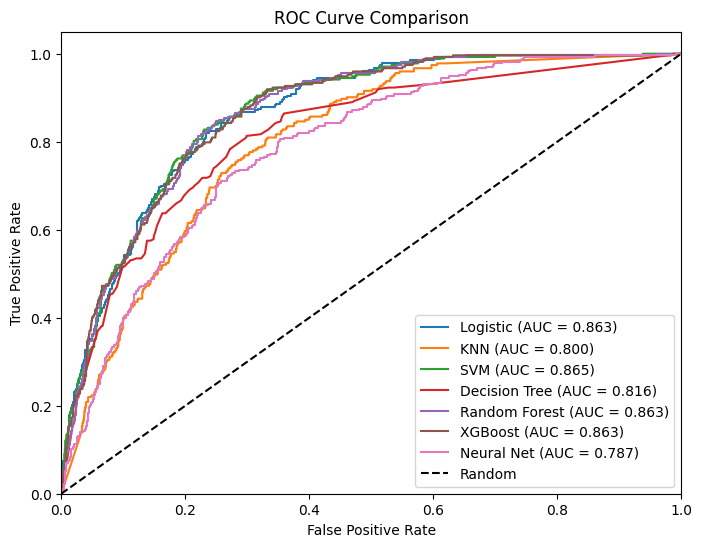

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0,1], [0,1], 'k--', label="Random")  # diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.show()

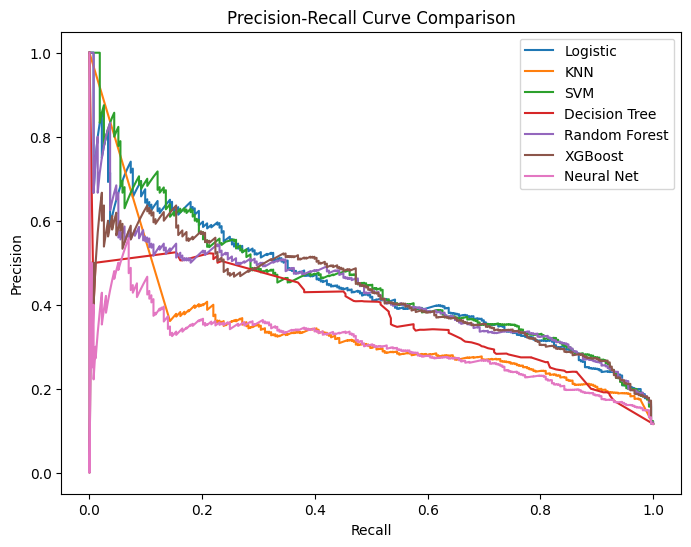

In [ ]:
plt.figure(figsize=(8,6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    plt.plot(recall, precision, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.show()

**Ensembles(Stacking)**

In [ ]:
print(np.isnan(X_train).sum())

alcohol_use_frequency_last_12m                0
bp_high_ever                                  0
cholesterol_high_ever                         0
insurance_covered                             0
insurance_private                             0
insurance_medicare                            0
insurance_medicaid                            0
care_delayed_due_to_cost                      0
self_rated_health                             7
usual_place_for_care                          6
poverty_income_ratio                          0
total_savings                                 0
nighttime_urination_frequency              5223
oral_health_self_rating                      11
gum_disease                                   7
mouth_pain                                 3180
difficulty_chewing                         3178
frequency_moderate_activity                   0
duration_moderate_activity                    0
frequency_vigorous_activity                   0
duration_vigorous_activity              

In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

estimators = [
    ('Logistic', model),
    ('KNN', knn_pipeline),
    ('SVM', svm_pipeline),
    ('DecisionTree', grid_dt.best_estimator_),
    ('RandomForest', grid_rf.best_estimator_),
    ('XGBoost', grid_xgb.best_estimator_),
]

stack_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(),
    cv=5,              # 5-fold cross-validation for OOF predictions
    passthrough=True, # if True, original features are fed to meta-model as well
    n_jobs=1
)

stack_model.fit(X_train, y_train)

y_pred = stack_model.predict(X_test)
y_pred_proba = stack_model.predict_proba(X_test)[:,1]  # for ROC-AUC

from sklearn.metrics import accuracy_score, roc_auc_score

print("Stacked Accuracy:", accuracy_score(y_test, y_pred))
print("Stacked ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:10:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:12:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:12:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Bhoomi\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:12:46] WARNING: C:\a

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values